In [31]:
'''Importing all relevant packages'''
import pandas as pd
import numpy as np
import yfinance as yf

from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
import matplotlib.pyplot as plt

In [32]:
'''Reading the Ovtlyr Data, Cleaning and Sorting'''
df = pd.read_csv('Input/Stock_Wise_Data_SectorSpyders - Energy.csv')
df = df.rename(columns={'Quotedate':'Date','StockSymbol':'Ticker',' ClosePrice ':'Close','Bull Per FullStock (Normal)':'Bull_per_norm','Bull Per FullStock (Active)':'Bull_per_act'})
df['Date'] = pd.to_datetime(df['Date'])
df = df.drop(columns=['Communication.Services FG Value',
       'Consumer.Discretionary FG Value', 'Consumer.Staples FG Value',
       'Energy FG Value', 'Financials FG Value', 'Health.Care FG Value',
       'Industrials FG Value', 'Information.Technology FG Value',
       'Materials FG Value', 'Real.Estate FG Value', 'Utilities FG Value'])
df['Signal'] = df['Signal'].fillna(0)
df['Close'] = df['Close'].str.replace('$', '')
df['Close'] = pd.to_numeric(df['Close'])
all_tickers = df['Ticker'].unique()
df = df.sort_values(by=['Date','Ticker'])

'''Have to shift the Heatmap and F&G as only yesterdays value is available today '''
df['Heatmap'] = df.groupby('Ticker')['Heatmap'].transform(lambda x: x.shift(1))
df['FG_Value'] = df.groupby('Ticker')['FG_Value'].transform(lambda x: x.shift(1))


In [33]:
'''Calculates the Rolling Z-Score of Heatmap and F&G, Rolling Z-Score of Slopes and Root Mean Square (RMS) of Heatmap and F&G'''
def generate_z_score(df,name):
       g = df.groupby('Ticker')[name]
       mu_g = g.transform(lambda x: x.rolling(120, min_periods=60).mean())
       sd_g = g.transform(lambda x: x.rolling(120, min_periods=60).std())
       df[f'{name}_z'] = ((df[name] - mu_g) / sd_g.where(sd_g > 1e-8)).clip(-5, 5)

def generate_slope_Z_score_rms(df,name):
       df[f'{name}_Slope10'] = df.groupby('Ticker')[name].transform(lambda x: x.diff(10))
       df[f'{name}_Slope10_mu'] = df.groupby('Ticker')[f'{name}_Slope10'].transform(lambda x: x.rolling(120, min_periods=60).mean())
       df[f'{name}_Slope10_std'] = df.groupby('Ticker')[f'{name}_Slope10'].transform(lambda x: x.rolling(120, min_periods=60).std())
       df[f'{name}_Slope10_z'] = ((df[f'{name}_Slope10'] - df[f'{name}_Slope10_mu']) / df[f'{name}_Slope10_std'].where(df[f'{name}_Slope10_std'] > 1e-8)).clip(-5, 5)

       df[f'{name}_Slope10_rms'] = df.groupby('Ticker')[f'{name}_Slope10'].transform(lambda x: np.sqrt((x**2).rolling(60).mean()))

generate_z_score(df=df,name='Heatmap')
generate_z_score(df=df,name='FG_Value')
generate_slope_Z_score_rms(df=df,name='Heatmap')
generate_slope_Z_score_rms(df=df,name='FG_Value')

In [34]:
'''Can be used to check if features are ADF and KPSS stationary'''
rows = []
for tik in all_tickers:
    df0 = df[df['Ticker'] == tik]['Heatmap_Slope10_z'].dropna()
    rows.append({
        'Ticker': tik,
        'ADF p-value': adfuller(df0, result_object=False)[1],
        'KPSS p-value': kpss(df0, result_object=False)[1],
    })

stationarity_df = pd.DataFrame(rows).set_index('Ticker')
stationarity_df['Stationary (5%)'] = (stationarity_df['ADF p-value'] < 0.05) & (stationarity_df['KPSS p-value'] > 0.05)
stationarity_df

C:\Users\scott\AppData\Local\Temp\ipykernel_15852\2150609610.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  'KPSS p-value': kpss(df0, result_object=False)[1],
C:\Users\scott\AppData\Local\Temp\ipykernel_15852\2150609610.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  'KPSS p-value': kpss(df0, result_object=False)[1],
C:\Users\scott\AppData\Local\Temp\ipykernel_15852\2150609610.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  'KPSS p-value': kpss(df0, result_object=False)[1],
C:\Users\scott\AppData\Local\Temp\ipykernel_15852\2150609610.py:8: InterpolationWarning: The test statistic is outside of the range of p-value

,ADF p-value,KPSS p-value,Stationary (5%)
Ticker,,,
XLE,3.928218e-18,0.1,True
XLF,2.809415e-18,0.1,True
XLI,5.502048e-22,0.1,True
XLK,5.272877e-21,0.1,True
XLP,4.631845e-22,0.1,True
XLU,2.061595e-23,0.1,True
XLV,9.571427e-18,0.1,True
XLY,8.932233e-19,0.1,True
XLB,3.419379e-19,0.1,True


In [35]:
'''Downloads OHLC data for ETFs, Calcuates ATR, and Switches the Close price to yfinance'''
tickers = all_tickers.tolist()
raw = yf.download(tickers,
                  start=df['Date'].min() - pd.Timedelta(days=120),   # ATR warm-up
                  end=df['Date'].max() + pd.Timedelta(days=1),
                  auto_adjust=False, progress=False, interval='1d')

def atr_wilder(d, n=14):
    pc = d['Close'].shift(1)
    tr = pd.concat([d['High'] - d['Low'],
                    (d['High'] - pc).abs(),
                    (d['Low'] - pc).abs()], axis=1).max(axis=1)
    return tr.ewm(alpha=1/n, adjust=False, min_periods=n).mean()

frames = []
for t in tickers:
    d = raw.xs(t, axis=1, level=1)[['High', 'Low', 'Close']].dropna().copy()
    d['ATR14'] = atr_wilder(d)
    d['ATR14_pct'] = d['ATR14'] / d['Close']
    d = d.rename(columns={'Close': 'YF_Close'})
    d['Ticker'] = t
    frames.append(d.reset_index())          # index is named 'Date'

ohlc = pd.concat(frames, ignore_index=True)
df = df.merge(ohlc, on=['Date', 'Ticker'], how='left')

df['Close'] = df['YF_Close'] #use yfinance instead of ovtlyr close data
df['Price'] = df.groupby('Ticker')['Close'].transform(lambda x: x.shift(-1))
df['Log_Close'] = np.log(df['Close'])
display(df.groupby('Ticker')['ATR14'].apply(lambda s: s.isna().sum()))

Ticker
XLB     0
XLC     0
XLE     0
XLF     0
XLI     0
XLK     0
XLP     0
XLRE    0
XLU     0
XLV     0
XLY     0
Name: ATR14, dtype: int64

W_MA = 200,150,100,50 \
W_SLOPE = 21,20,10-20,5-10

(200,21) = Long Trend Filter \
(150,20) = Weinstein's Original\
(100,10-20) = Medium Trend Filter\
(50,5-10) = Short Trend Filter (More Whipsaw)

In [36]:
'''Calcuates Stages a ETF is in under different configs'''
CONFIGS = {
    'Long_trend': (200, 21),
    'Weinstein':  (150, 20),
    'Medium':     (100, 15),   # midpoint of 10-20
    'Fast':       (50, 10),    # top of 5-10; use 7 for the midpoint
}


def add_stage(df, name, w_ma, w_slope, eps=0.0):
    ma = df.groupby('Ticker')['Close'].transform(lambda x: x.rolling(w_ma).mean())
    slope = ma.groupby(df['Ticker']).pct_change(w_slope, fill_method=None)
    dist = df['Close'] / ma - 1
    ok = dist.notna() & slope.notna()

    above, rising, falling = dist > 0, slope > eps, slope < -eps
    stage = pd.Series(np.select([above & rising, ~above & falling, above], [2, 4, 3], default=1),
                      index=df.index).where(ok)

    df[f'Dist_MA_{name}'] = dist
    df[f'MA_slope_{name}'] = slope
    df[f'Stage_{name}'] = stage
    df[f'Stage2_{name}'] = (stage == 2).astype(float).where(ok)
    # df[f'Stage2_Heatmap_slope_{name}'] = ((stage == 2) & (df['Heatmap_Slope10_z'] > 1)).astype(float).where(ok & df['Heatmap_Slope10_z'].notna())
    df[f'Stage2_Heatmap_Slope_{name}'] = ((stage == 2) & ((df['Heatmap_Slope10'] > df['Heatmap_Slope10_rms']))).astype(float).where(ok & df['Heatmap_Slope10_rms'].notna())
    df[f'Stage2_FG_Value_Slope_{name}'] = ((stage == 2) & ((df['FG_Value_Slope10'] > df['FG_Value_Slope10_rms']))).astype(float).where(ok & df['FG_Value_Slope10_rms'].notna())


for name, (w_ma, w_slope) in CONFIGS.items():
    add_stage(df, name, w_ma, w_slope)
    

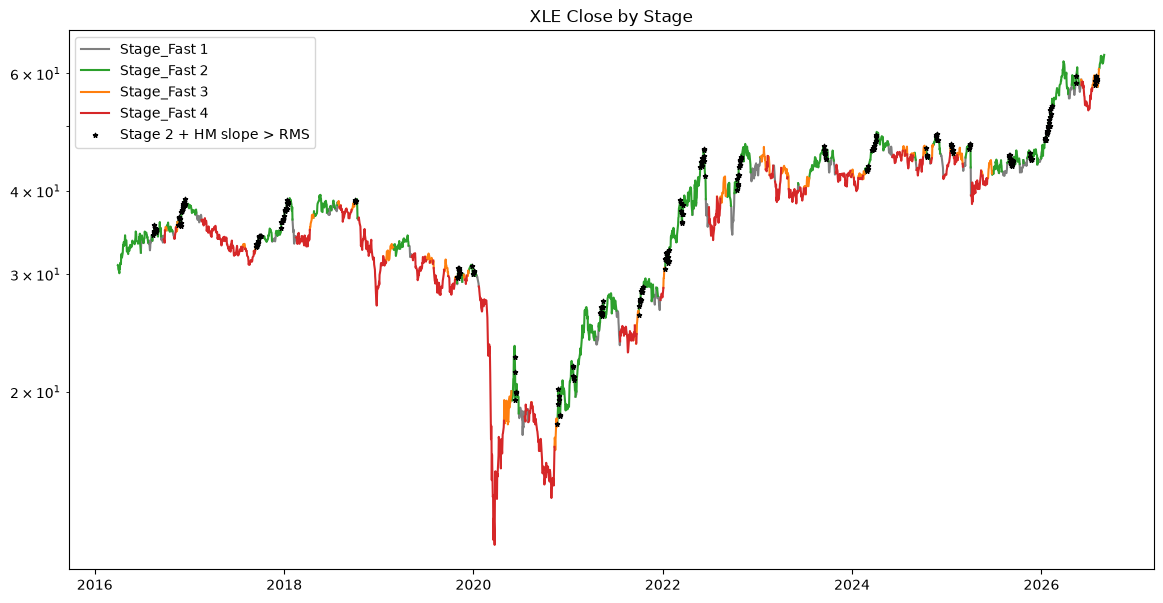

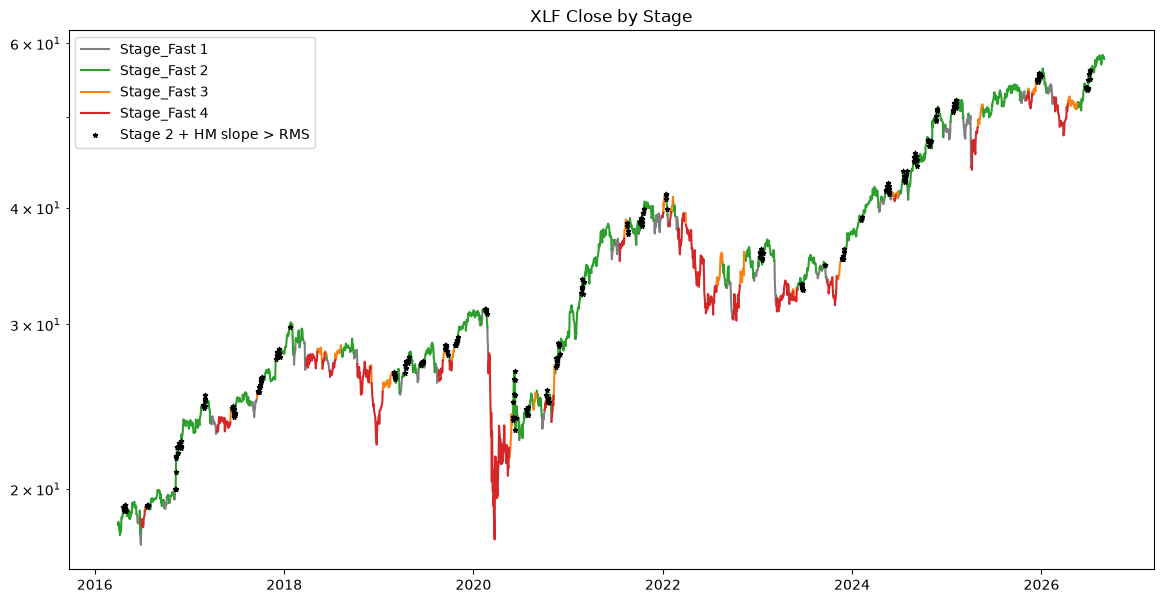

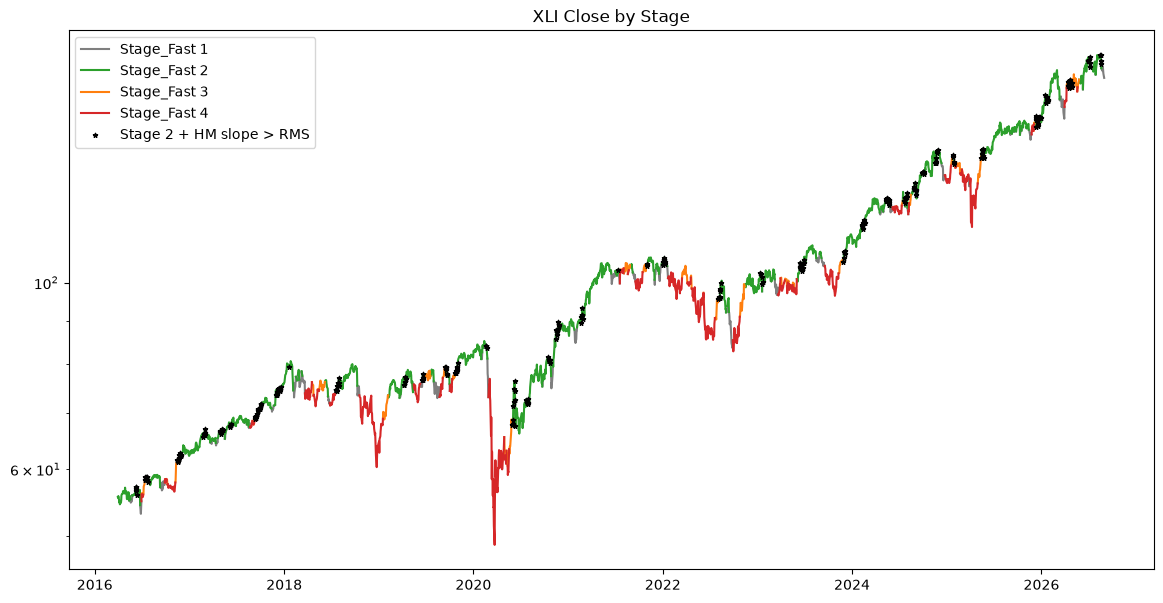

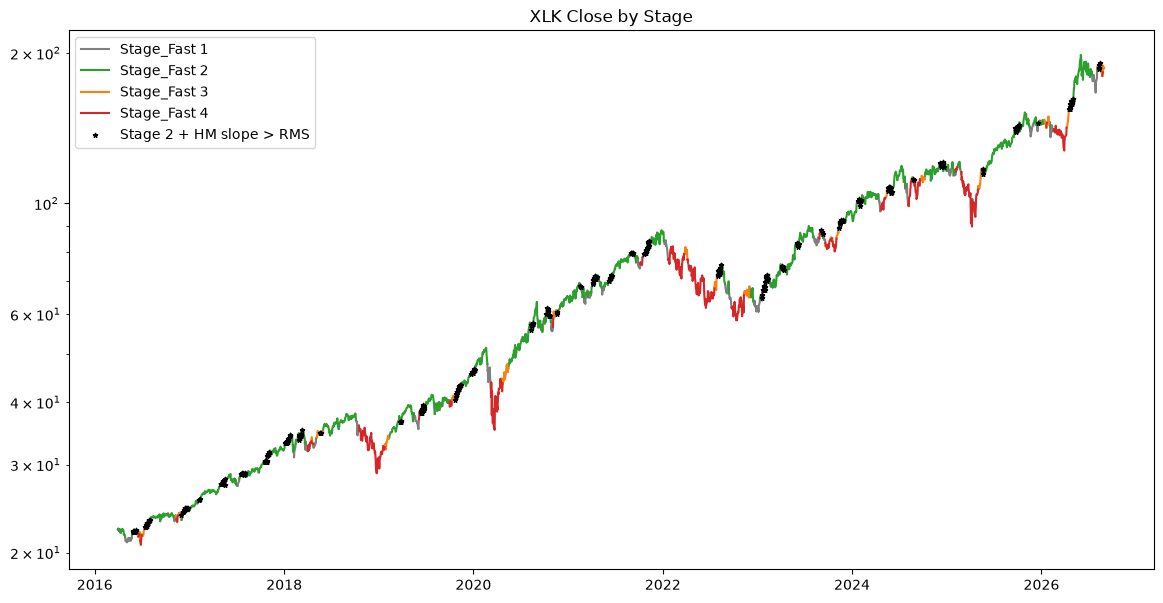

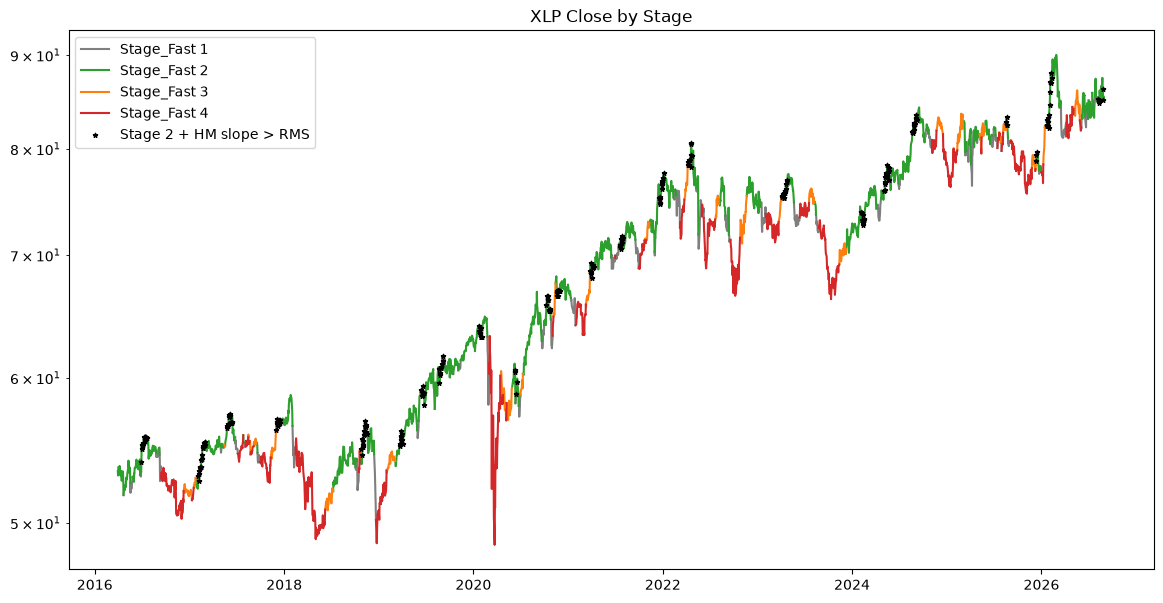

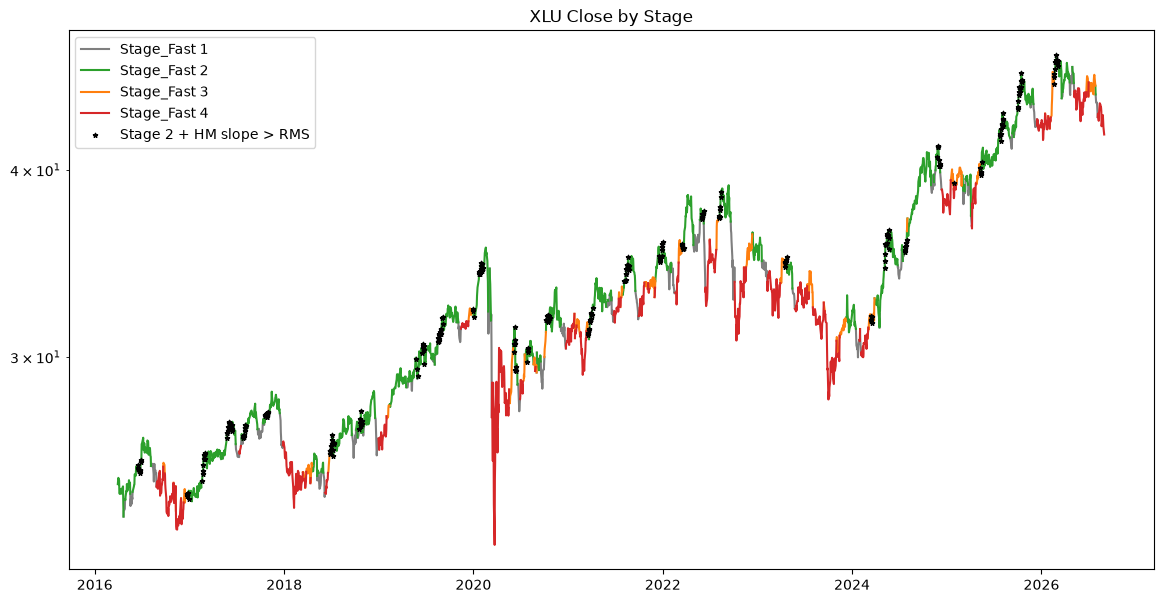

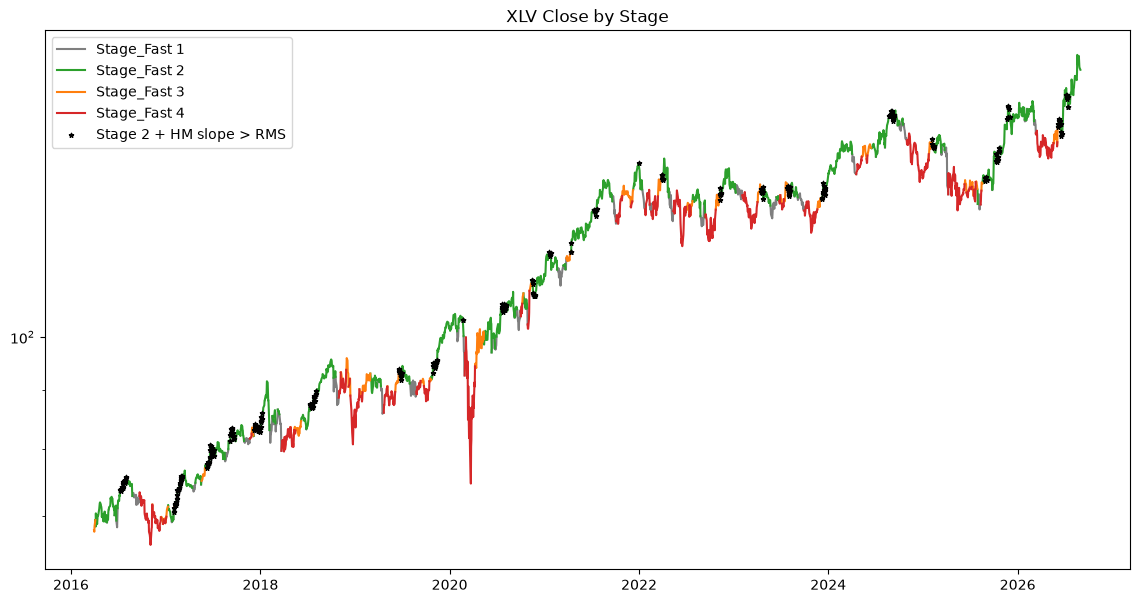

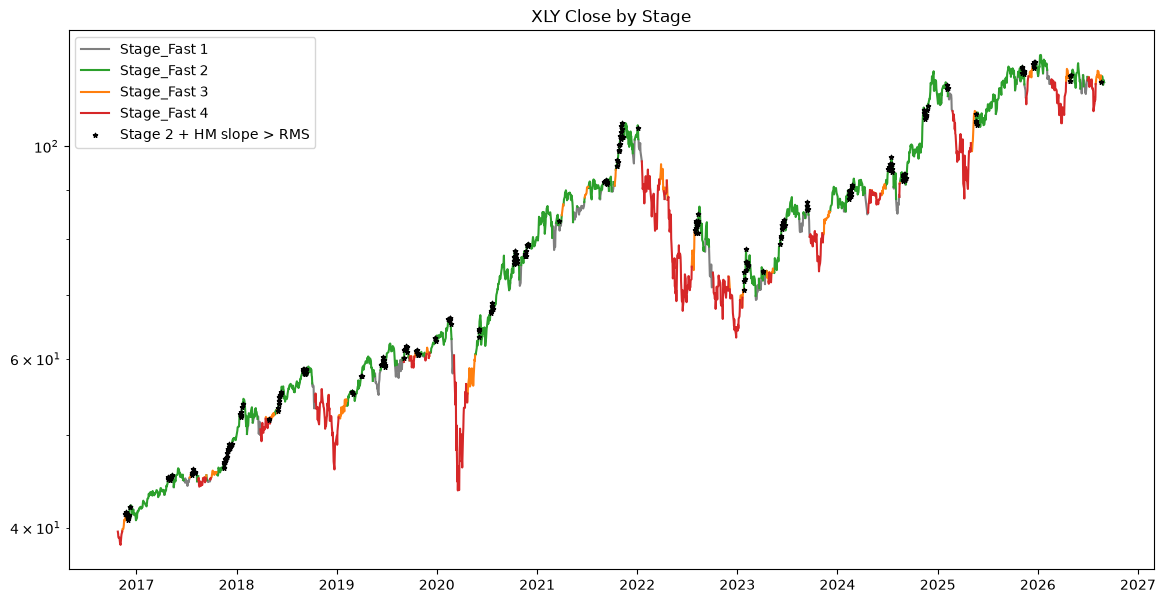

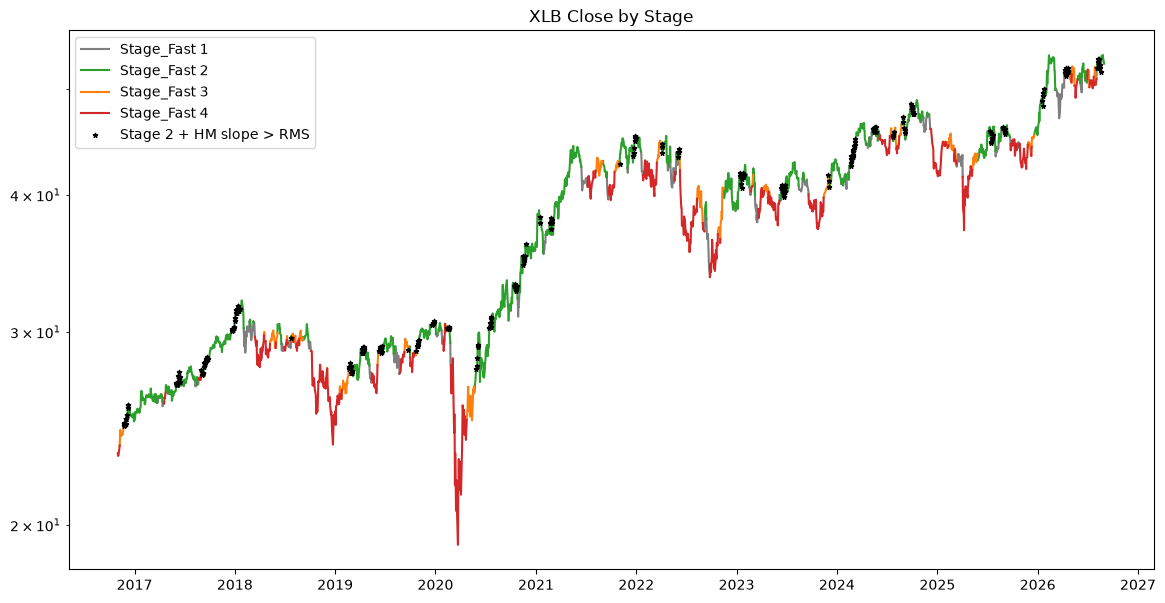

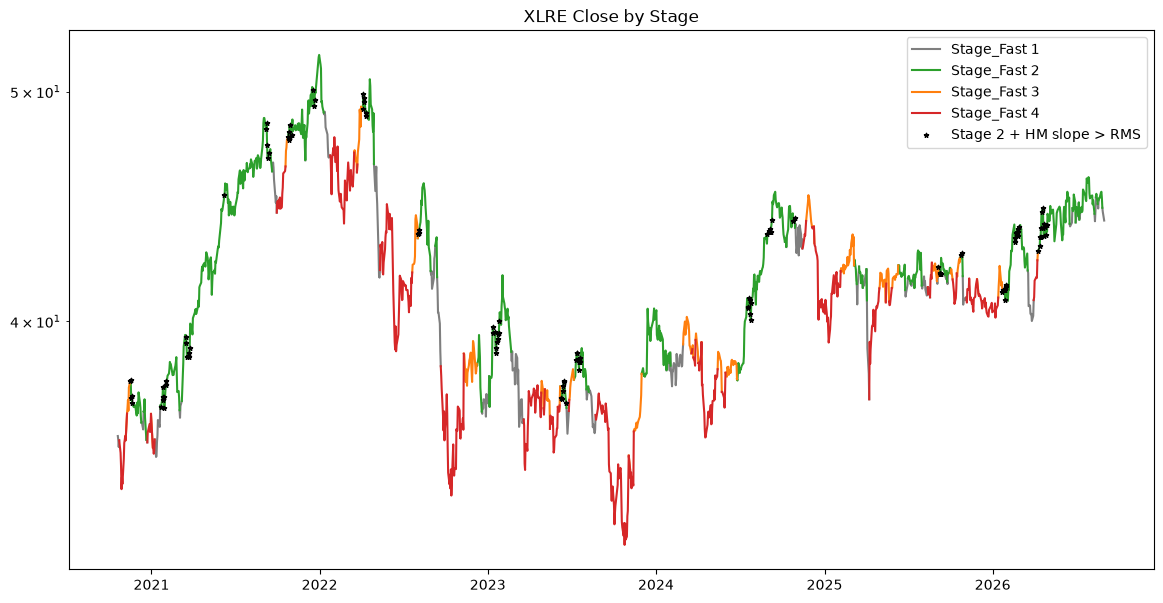

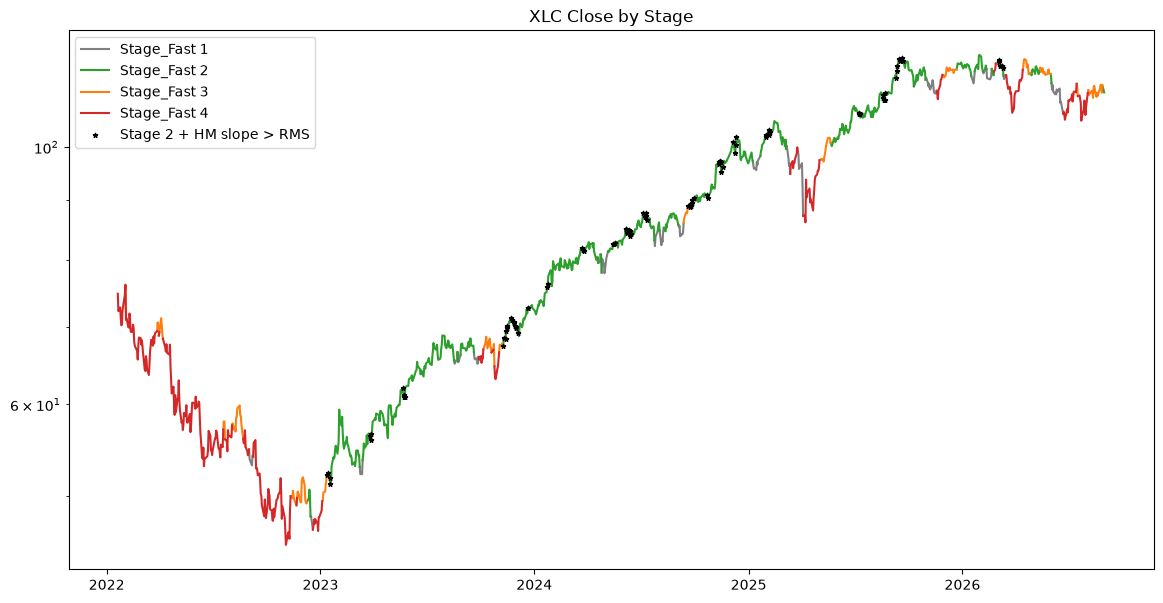

In [51]:
'''Plots all ETFs Price data with different stages coloured, also plots Heatmap spikes on stage 2'''
CONFIG = 'Fast'
for TIK in all_tickers:
    df0 = df[df['Ticker'] == TIK].dropna(subset=[f'Stage_{CONFIG}']).set_index('Date')

    colors = {1: 'tab:gray', 2: 'tab:green', 3: 'tab:orange', 4: 'tab:red'}

    fig, ax = plt.subplots(figsize=(14, 7))
    for st, c in colors.items():
        m = df0[f'Stage_{CONFIG}'] == st
        seg = df0['Close'].where(m | m.shift(1, fill_value=False))   # +1 bar so segments join
        ax.plot(seg, color=c, label=f'Stage_{CONFIG} {st}')

    col1 = f'Stage2_Heatmap_Slope_{CONFIG}'   # assumes name == CONFIG
    sig1 = df0[col1] == 1

    col2 = f'Stage2_FG_Value_Slope_{CONFIG}'   # assumes name == CONFIG
    sig2 = df0[col2] == 1
    
    ax.scatter(df0.index[sig1], df0['Close'][sig1], color='black', marker='*',s=10, zorder=5, label='Stage 2 + HM slope > RMS')
    # ax.scatter(df0.index[sig2], df0['Close'][sig2], color='blue', marker='*',s=10, zorder=5, label='Stage 2 + FG slope > RMS')
    ax.set_title(f'{TIK} Close by Stage')
    ax.legend()
    ax.set_yscale('log')
    # plt.savefig(f'Output/Figures/{TIK}_stage_plot.png')
    plt.show()

In [38]:
'''Drops any values that does not have a heatmap (not on the platform yet), and burn-in periods of indicators'''
df0 = df.sort_values(['Ticker','Date']).dropna()
all_df = df0

'''Splits the data into 80:20 test trian split. 2016-2024 and 2024-2026'''
SPLIT = '2024-01-01'
train,test = df0[df0['Date'] <= pd.to_datetime(SPLIT)],df0[df0['Date'] > pd.to_datetime(SPLIT)]

# train.to_csv('Output/Transformed_Sector_data_train.csv')

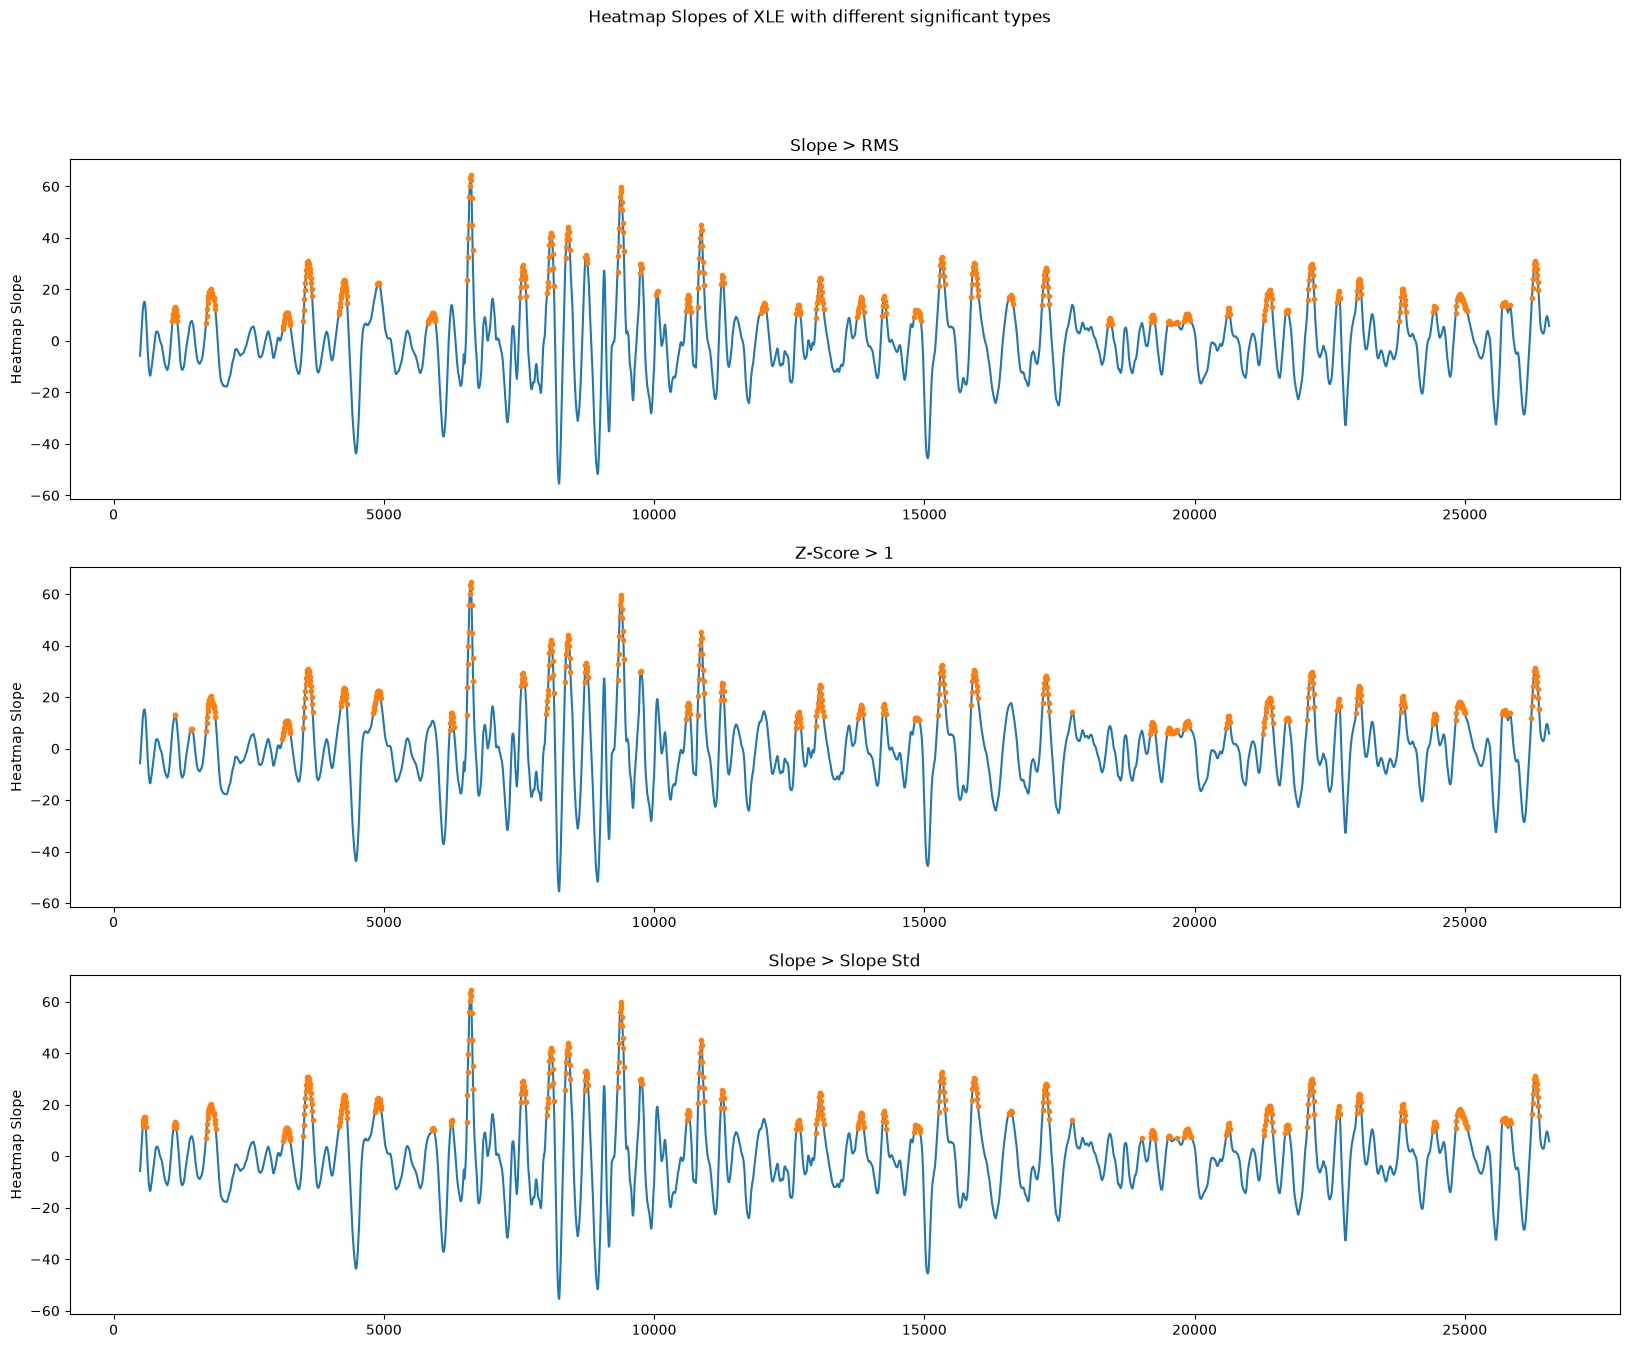

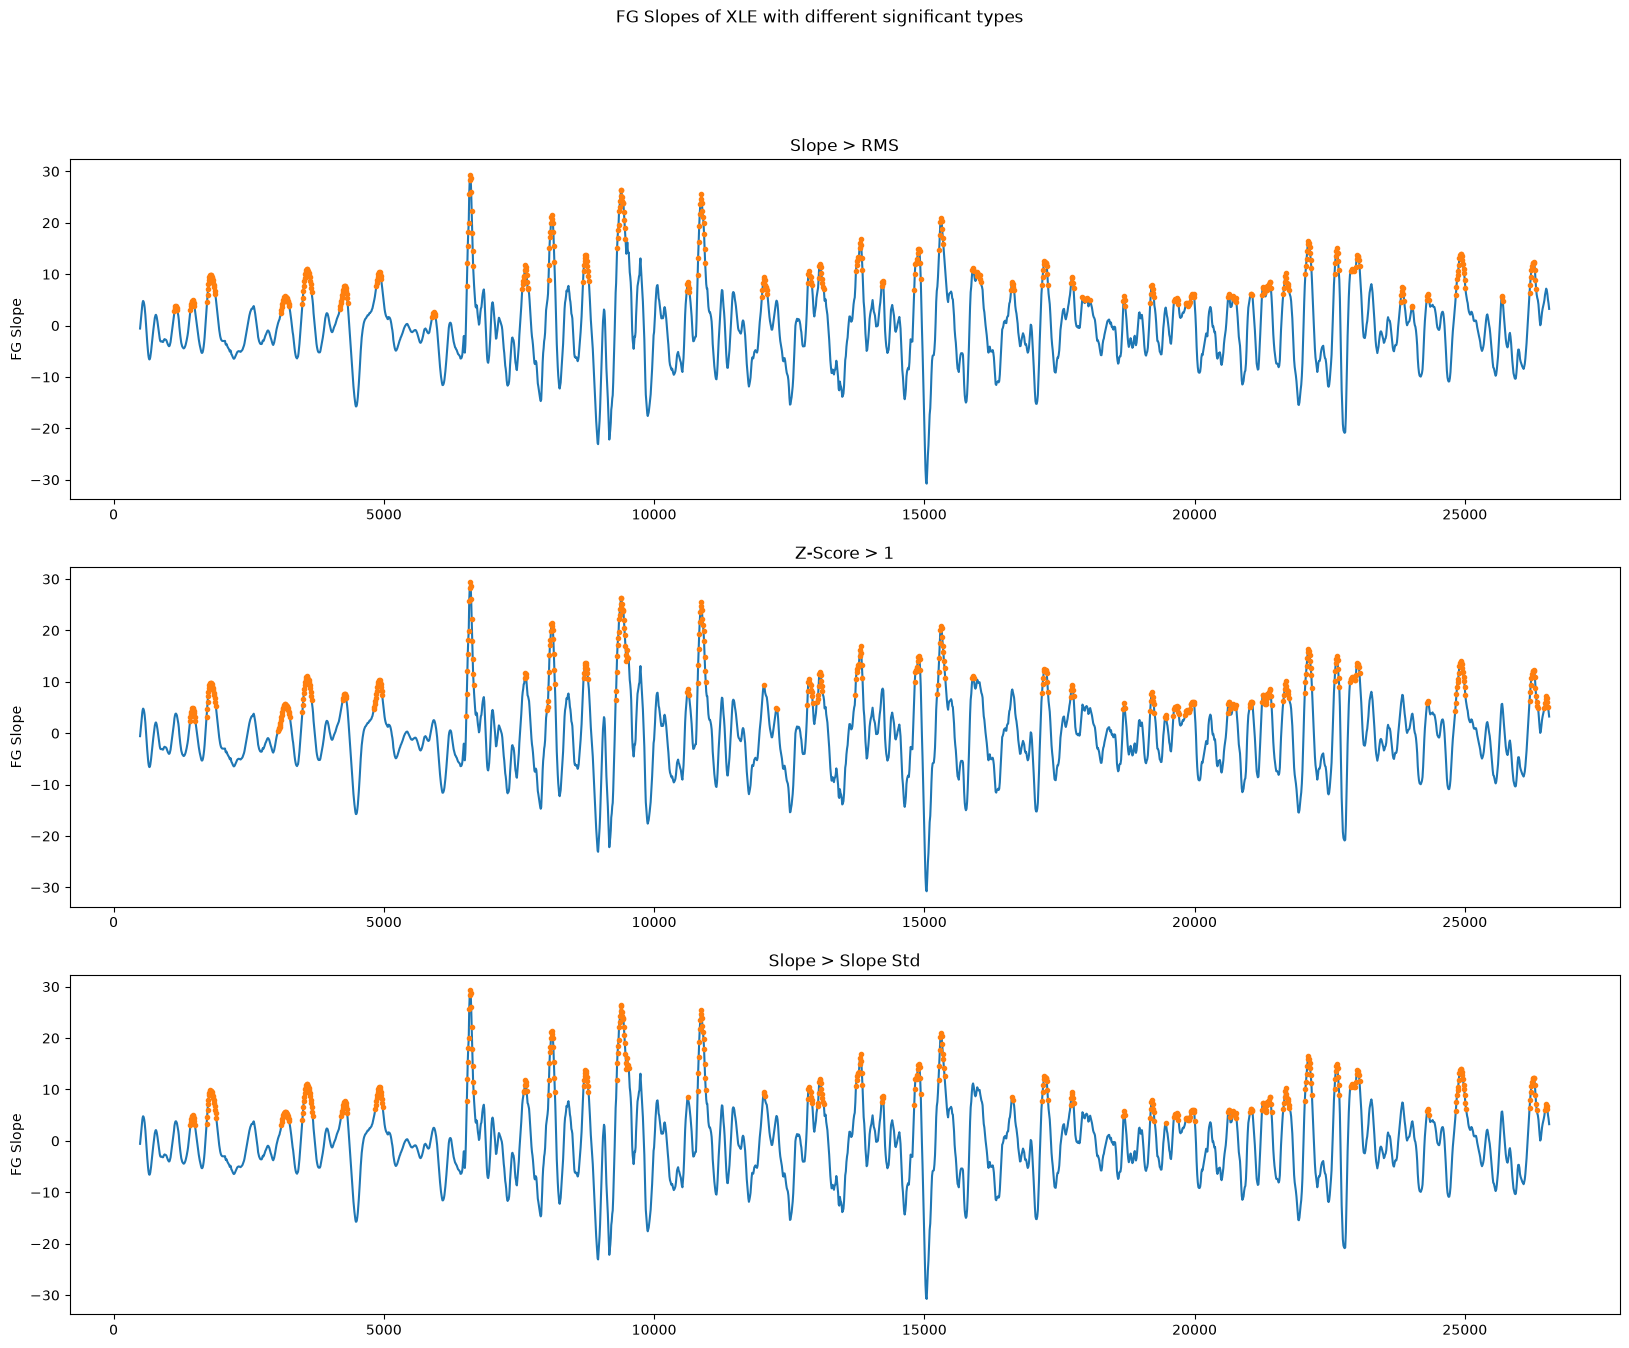

In [39]:
'''Example of different spike dectection techniques (RMS, Z-Score, Std) on Heatmap Slope and F&G Slope'''
tik = 'XLE'
df0 = df[df['Ticker'] == tik][['Date','Heatmap','Heatmap_Slope10','Heatmap_Slope10_std','Heatmap_Slope10_z','Heatmap_Slope10_rms','FG_Value','FG_Value_Slope10','FG_Value_Slope10_std','FG_Value_Slope10_z','FG_Value_Slope10_rms']].dropna()


def heatmap_spike_plotter(df,base_plot,base_plot_ylab,title):
    df = df.dropna()
    fig, (ax1,ax2,ax3) = plt.subplots(3,1,figsize = (20,15))
    ax1.plot(df[base_plot])
    ax1.plot(df[df[base_plot] > df[f'{base_plot}_rms']][base_plot],'.')
    ax1.set_title('Slope > RMS'),ax1.set_ylabel(base_plot_ylab)

    ax2.plot(df[base_plot])
    ax2.plot(df[df[f'{base_plot}_z'] > 1][base_plot],'.')
    ax2.set_title('Z-Score > 1'),ax2.set_ylabel(base_plot_ylab)

    ax3.plot(df[base_plot])
    ax3.plot(df[df[base_plot] > df[f'{base_plot}_std']][base_plot],'.')
    ax3.set_title('Slope > Slope Std'),ax3.set_ylabel(base_plot_ylab)
    fig.suptitle(title)

heatmap_spike_plotter(df=df0,base_plot='Heatmap_Slope10',base_plot_ylab = 'Heatmap Slope',title=f"Heatmap Slopes of {tik} with different significant types")
heatmap_spike_plotter(df=df0,base_plot='FG_Value_Slope10',base_plot_ylab = 'FG Slope',title=f"FG Slopes of {tik} with different significant types")

In [40]:
'''Backtesting function for all etfs, each made independently
ASSUMPTION: 
- No leverage cost for borrowing money'''

ENTRY_TYPE = 'Heatmap'
COST_BPS = 5
TRAIL_ATR = 1

def make_trade(d, i, x, is_open):
    path = d['Close'][i:x + 1]
    p0, a0 = path[0], d['ATR14'][i]
    c = COST_BPS / 1e4
    entry_px, exit_px = p0 * (1 + c), path[-1] * (1 - c)
    ret_g = 100 * (path[-1] / p0 - 1)          # gross
    ret   = 100 * (exit_px / entry_px - 1)     # net
    mfe   = 100 * (path.max() / p0 - 1)
    return {
        'Ticker': d['Ticker'][0],
        'entry_date': d['Date'][i], 'exit_date': d['Date'][x],
        'bars': x - i,
        'entry': entry_px, 'exit': exit_px,
        'ret%': ret,
        'ret_gross%': ret_g,
        'MFE%': mfe,
        'capture%': 100 * ret_g / mfe if mfe > 0 else np.nan,   # gross vs gross MFE
        'MAE%': 100 * (path.min() / p0 - 1),
        'ATR_entry': a0,
        'ATR_pct': 100 * a0 / p0,
        'ret_ATR': (exit_px - entry_px) / a0,                   # net
        'MFE_ATR': (path.max() - p0) / a0,
        'MAE_ATR': (path.min() - p0) / a0,
        'bars_to_MFE': int(path.argmax()),
        'bars_to_MAE': int(path.argmin()),
        'open': is_open,
    }

def trades_for(g, entry_fn, exit_fn):
    g = g.sort_values('Date').reset_index(drop=True)
    d = {c: g[c].to_numpy() for c in g.columns}   # column -> numpy array
    n, active, i, out = len(g), False, None, []

    for t in range(n):
        if active and exit_fn(d, t, i):            # exit checked first, never on entry bar
            out.append(make_trade(d, i, t, is_open=False))
            active = False
        if not active and entry_fn(d, t):          # can re-enter on the exit bar
            active, i = True, t

    if active:                                     # close any open position at end of data
        out.append(make_trade(d, i, n - 1, is_open=True))
    return out



# Conditions: (d, t) for entry, (d, t, i) for exit, where t = current bar, i = entry bar
entry_fn = lambda d, t: d[f'Stage2_{ENTRY_TYPE}_Slope_Fast'][t] == 1
exit_fn = lambda d, t, i: (d['Stage_Fast'][t] != 2 or d['Close'][t] <= d['Close'][i:t + 1].max() - TRAIL_ATR * d['ATR14'][i]) #Non-Stage 2 and Trailing Stop

trades = pd.DataFrame([tr for _, g in train.groupby('Ticker')
                       for tr in trades_for(g, entry_fn, exit_fn)])

summary = trades[~trades['open']].groupby('Ticker').agg(
    n=('ret%', 'size'),
    bars_med=('bars', 'median'),
    win=('ret%', lambda s: (s > 0).mean()),
    ATR_pct_med=('ATR_pct', 'median'),
    ret_per_mean=('ret%', 'mean'),
    MFE_per_mean=('MFE%', 'mean'),
    capture_med=('capture%', 'median'),
    MAE_per_mean=('MAE%', 'mean'),
    ret_ATR_mean=('ret_ATR', 'mean'),
    ret_ATR_med=('ret_ATR', 'median'),
    MFE_ATR_mean=('MFE_ATR', 'mean'),
    MAE_ATR_mean=('MAE_ATR', 'mean'),
    MFE_ATR_med=('MFE_ATR', 'median'),
    MAE_ATR_med=('MAE_ATR', 'median'),
)
summary['MFE/|MAE| %']   = summary['MFE_per_mean'] / summary['MAE_per_mean'].abs()
summary['MFE/|MAE| ATR'] = summary['MFE_ATR_mean'] / summary['MAE_ATR_mean'].abs()
summary

,n,bars_med,win,ATR_pct_med,ret_per_mean,MFE_per_mean,capture_med,MAE_per_mean,ret_ATR_mean,ret_ATR_med,MFE_ATR_mean,MAE_ATR_mean,MFE_ATR_med,MAE_ATR_med,MFE/|MAE| %,MFE/|MAE| ATR
Ticker,,,,,,,,,,,,,,,,
XLB,32,8.5,0.375000,1.529257,-0.093242,2.390693,-32.735412,-1.073475,0.161642,-0.694311,1.726943,-0.681992,0.857817,-0.636349,2.227059,2.532205
XLC,7,12.0,0.571429,1.586407,2.772186,4.923729,52.074563,-0.798986,1.489784,1.010979,2.745455,-0.486969,2.538187,-0.399854,6.162474,5.637845
XLE,36,5.0,0.416667,2.527327,0.130685,3.914622,36.861320,-2.040951,0.183828,-0.365527,1.641064,-0.765990,0.967851,-0.781271,1.918039,2.142409
XLF,43,6.0,0.441860,1.561954,0.415737,2.848322,34.920572,-1.079425,0.332670,-0.376777,1.762128,-0.659729,1.145054,-0.581577,2.638741,2.670988
XLI,36,7.0,0.500000,1.313318,0.686512,2.970312,44.429745,-0.995578,0.637590,0.087096,2.178354,-0.657369,1.627803,-0.414558,2.983506,3.313749
XLK,39,11.0,0.589744,1.500039,1.504308,3.861917,51.379249,-0.711305,1.145076,0.851992,2.813664,-0.457498,2.221201,-0.101259,5.429340,6.150114
XLP,31,6.0,0.451613,1.065808,0.011580,1.745695,23.171038,-0.742262,0.122599,-0.158524,1.711135,-0.654297,1.131716,-0.539062,2.351859,2.615225
XLRE,13,7.0,0.307692,1.653449,-0.184466,2.158805,-20.762150,-0.904696,-0.206867,-0.322378,1.244372,-0.579091,0.986584,-0.307294,2.386223,2.148839
XLU,34,9.5,0.500000,1.395271,0.668064,2.684102,33.646629,-0.659094,0.666770,0.159860,2.070184,-0.411671,1.573975,-0.219729,4.072408,5.028737


count    2601.000000
mean        1.876586
std         1.999171
min         0.000000
25%         0.000000
50%         1.000000
75%         3.000000
max         8.000000
Name: n_open, dtype: float64

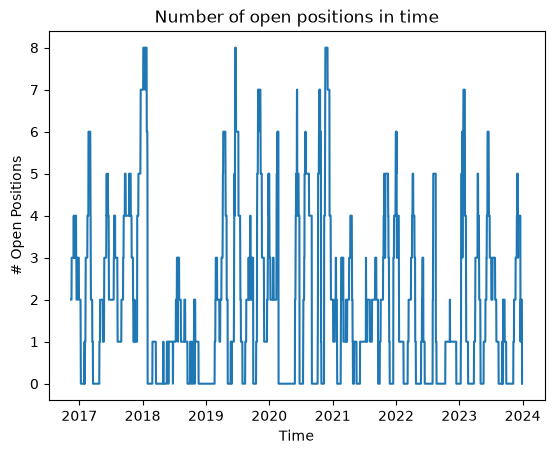

In [41]:
'''Analyzes the number of open positions on each date '''
trades['entry_date'] = pd.to_datetime(trades['entry_date'])
trades['exit_date']  = pd.to_datetime(trades['exit_date'])

idx = pd.date_range(trades['entry_date'].min(), trades['exit_date'].max(), freq='D')  # 'B' for weekdays only

delta = (trades.groupby('entry_date').size()
         .sub(trades.groupby('exit_date').size(), fill_value=0)
         .reindex(idx, fill_value=0))

n_open = delta.cumsum().rename('n_open')   # positions held at the close of each date
plt.plot(n_open),plt.title('Number of open positions in time'),plt.ylabel('# Open Positions'),plt.xlabel('Time')
n_open.describe()

In [42]:
'''Stat Descriptions of trades, split into All, Winners, and Losers'''
print('=== All Trades ===')
display(trades.describe().drop(columns=['entry_date','exit_date']))
print('=== Winning Trades ===')
display(trades[trades['ret%'] > 0].describe().drop(columns=['entry_date','exit_date']))
print('=== Losing Trades ===')
display(trades[trades['ret%'] < 0].describe().drop(columns=['entry_date','exit_date']))

=== All Trades ===


,bars,entry,exit,ret%,ret_gross%,MFE%,capture%,MAE%,ATR_entry,ATR_pct,ret_ATR,MFE_ATR,MAE_ATR,bars_to_MFE,bars_to_MAE
count,344.000000,344.000000,344.000000,344.000000,344.000000,344.000000,280.000000,344.000000,344.000000,344.000000,344.000000,344.000000,344.000000,344.000000,344.000000
mean,9.688953,55.090264,55.454614,0.619001,0.719671,2.953245,-126.309075,-0.975866,0.814522,1.564873,0.565259,2.068433,-0.602400,7.101744,2.590116
min,1.000000,17.913953,18.370809,-9.512177,-9.421644,0.000000,-10197.826087,-9.421644,0.196912,0.603456,-3.207721,0.000000,-3.120264,0.000000,0.000000
25%,4.000000,30.986735,31.365559,-1.494140,-1.395585,0.340564,-78.133031,-1.420442,0.493707,1.105454,-1.082330,0.245070,-1.001226,1.000000,0.000000
50%,7.000000,46.453215,46.836571,-0.276604,-0.176831,1.925314,32.514719,-0.636553,0.689004,1.405766,-0.183129,1.367209,-0.411556,4.000000,1.000000
75%,13.000000,73.750604,74.953757,2.321678,2.424051,4.476634,61.966571,0.000000,1.058410,1.794383,1.730590,3.048067,0.000000,10.000000,4.000000
max,46.000000,141.560750,139.920010,13.491763,13.605312,15.944199,100.000000,0.000000,2.392340,5.092304,14.074437,15.225974,0.000000,41.000000,16.000000
std,8.299376,27.921792,28.186483,3.302814,3.306118,3.297837,753.173841,1.302652,0.446826,0.684750,2.326822,2.325498,0.665015,7.962639,3.154527


=== Winning Trades ===


,bars,entry,exit,ret%,ret_gross%,MFE%,capture%,MAE%,ATR_entry,ATR_pct,ret_ATR,MFE_ATR,MAE_ATR,bars_to_MFE,bars_to_MAE
count,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000
mean,15.111801,56.022345,57.825235,3.302600,3.405954,5.380348,57.281217,-0.184101,0.799189,1.486671,2.420904,3.835782,-0.129862,12.403727,0.795031
min,2.000000,17.913953,19.445272,0.044461,0.144555,0.865004,9.714617,-1.442740,0.196912,0.604367,0.049727,0.723286,-0.935043,1.000000,0.000000
25%,9.000000,31.920953,33.613186,1.204141,1.305396,3.161743,42.635668,-0.226247,0.441115,1.038892,0.804617,2.237377,-0.185763,6.000000,0.000000
50%,13.000000,48.294135,49.345314,2.620234,2.722905,4.463113,59.595917,0.000000,0.668787,1.329538,1.891371,3.209555,0.000000,10.000000,0.000000
75%,20.000000,74.327146,76.621674,4.669400,4.774122,6.495507,73.505803,0.000000,1.069238,1.784038,3.182551,4.698716,0.000000,17.000000,1.000000
max,46.000000,138.139042,139.920010,13.491763,13.605312,15.944199,100.000000,0.000000,2.392340,3.946802,14.074437,15.225974,0.000000,41.000000,8.000000
std,8.717076,28.548248,29.352247,2.712087,2.714801,3.224180,19.696865,0.334372,0.459507,0.629999,2.142846,2.279624,0.230505,8.442733,1.445329


=== Losing Trades ===


,bars,entry,exit,ret%,ret_gross%,MFE%,capture%,MAE%,ATR_entry,ATR_pct,ret_ATR,MFE_ATR,MAE_ATR,bars_to_MFE,bars_to_MAE
count,183.000000,183.000000,183.000000,183.000000,183.000000,183.000000,119.000000,183.000000,183.000000,183.000000,183.000000,183.000000,183.000000,183.000000,183.000000
mean,4.918033,54.270236,53.368985,-1.741979,-1.643671,0.817925,-374.695940,-1.672446,0.828012,1.633674,-1.067304,0.513553,-1.018131,2.437158,4.169399
min,1.000000,19.429710,18.370809,-9.512177,-9.421644,0.000000,-10197.826087,-9.421644,0.197463,0.603456,-3.207721,0.000000,-3.120264,0.000000,0.000000
25%,2.000000,30.537761,30.004990,-2.186548,-2.088685,0.000000,-317.856359,-2.088685,0.514271,1.178809,-1.352571,0.000000,-1.285821,0.000000,2.000000
50%,4.000000,45.647813,44.557712,-1.377349,-1.278677,0.388032,-125.881978,-1.307897,0.694044,1.504821,-1.025273,0.294238,-0.951348,1.000000,3.000000
75%,6.000000,73.028997,72.181390,-0.780795,-0.681526,1.079984,-33.143981,-0.745832,1.054314,1.812476,-0.556140,0.801476,-0.547573,4.000000,6.000000
max,22.000000,141.560750,139.370282,-0.000597,0.099452,8.043280,12.001038,0.000000,2.256915,5.092304,-0.000302,3.393035,0.000000,21.000000,16.000000
std,3.756146,27.411051,27.028309,1.454848,1.456304,1.249820,1110.191965,1.434319,0.436182,0.724273,0.663891,0.655225,0.644547,3.175306,3.399862


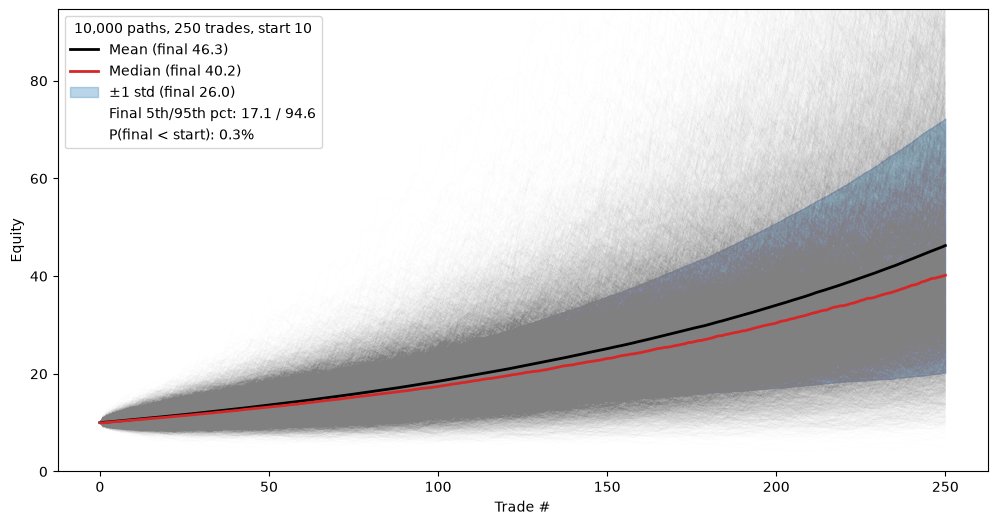

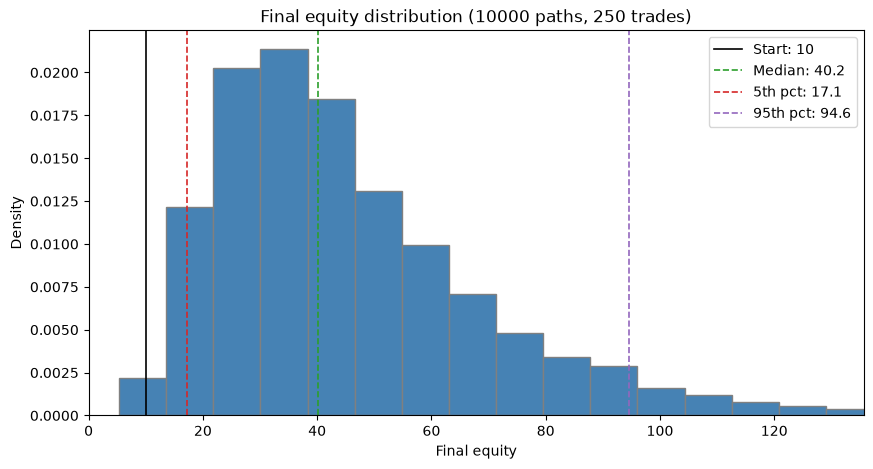

P(loss): 0.3%


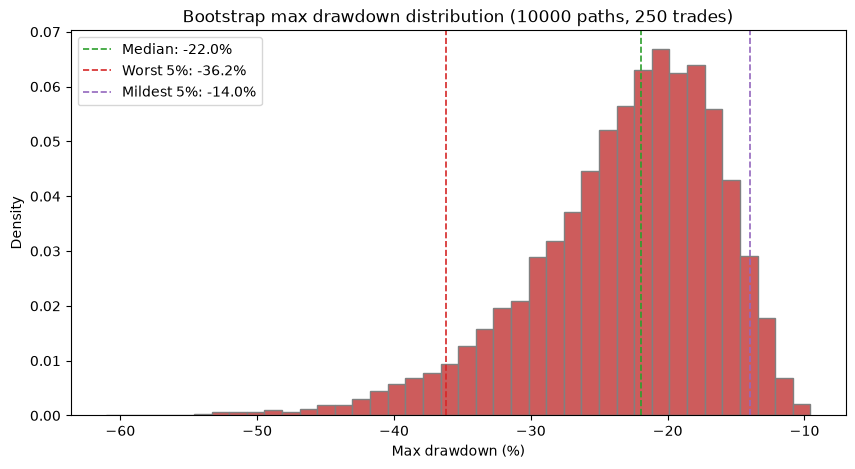

P(maxDD worse than -20%): 63.0%


In [43]:
'''Bootstrapping the trades to give a distribution of returns and drawdowns
    ASSUMPTIONS: 
    - That all the trades are IID
    - Sample is the full population
    - Bounded tails, no trade can be better or worse than what is in the sample 
    A better alternative may be regime bootstrapping
'''
rng = np.random.default_rng(420)
closed = trades[~trades['open']]
rets = closed['ret%'].to_numpy() / 100
N_PATHS, L, START = 10000, 250, 10

samples = rng.choice(rets, size=(N_PATHS, L), replace=True)
equity = START * np.cumprod(1 + samples, axis=1)
equity = np.hstack([np.full((N_PATHS, 1), START), equity])   # start all paths at START

mean, std = equity.mean(axis=0), equity.std(axis=0)
med = np.median(equity, axis=0)
x = np.arange(L + 1)

final = equity[:, -1]
p5, p95,p99 = np.percentile(final, [5, 95,99])
p_loss = (final < START).mean()

cap = p95
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(x, equity.T, color='gray', alpha=0.01, lw=0.7)
ax.plot(x, mean, color='k', lw=2, label=f'Mean (final {mean[-1]:.1f})')
ax.plot(x, med, color='tab:red', lw=2, label=f'Median (final {med[-1]:.1f})')
ax.fill_between(x, mean - std, mean + std, color='tab:blue', alpha=0.3,
                label=f'±1 std (final {std[-1]:.1f})')
ax.plot([], [], ' ', label=f'Final 5th/95th pct: {p5:.1f} / {p95:.1f}')
ax.plot([], [], ' ', label=f'P(final < start): {p_loss:.1%}')
ax.set_ylim(0, cap)
ax.set_xlabel('Trade #')
ax.set_ylabel('Equity')
ax.legend(title=f'{N_PATHS:,} paths, {L} trades, start {START}', loc='upper left')
plt.show()

final = equity[:, -1]
p5, med, p95 = np.percentile(final, [5, 50, 95])

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(final, bins=40, density=True, facecolor='steelblue', edgecolor='gray')
ax.axvline(START, color='k', lw=1.2, label=f'Start: {START}')
ax.axvline(med, color='tab:green', ls='--', lw=1.2, label=f'Median: {med:.1f}')
ax.axvline(p5, color='tab:red', ls='--', lw=1.2, label=f'5th pct: {p5:.1f}')
ax.axvline(p95, color='tab:purple', ls='--', lw=1.2, label=f'95th pct: {p95:.1f}')
ax.set_xlabel('Final equity')
ax.set_ylabel('Density')
ax.set_xlim(0,p99)
ax.set_title(f'Final equity distribution ({N_PATHS} paths, {L} trades)')
ax.legend()
plt.show()

print(f'P(loss): {(final < START).mean():.1%}')

peak = np.maximum.accumulate(equity, axis=1)
maxdd = (equity / peak - 1).min(axis=1) * 100          # % , negative

d5, dmed, d95 = np.percentile(maxdd, [5, 50, 95])       # d5 = worst 5%

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(maxdd, bins=40, density=True, facecolor='indianred', edgecolor='gray')
ax.axvline(dmed, color='tab:green', ls='--', lw=1.2, label=f'Median: {dmed:.1f}%')
ax.axvline(d5, color='tab:red', ls='--', lw=1.2, label=f'Worst 5%: {d5:.1f}%')
ax.axvline(d95, color='tab:purple', ls='--', lw=1.2, label=f'Mildest 5%: {d95:.1f}%')
ax.set_xlabel('Max drawdown (%)')
ax.set_ylabel('Density')
ax.set_title(f'Bootstrap max drawdown distribution ({N_PATHS} paths, {L} trades)')
ax.legend()
plt.show()

print(f'P(maxDD worse than -20%): {(maxdd < -20).mean():.1%}')

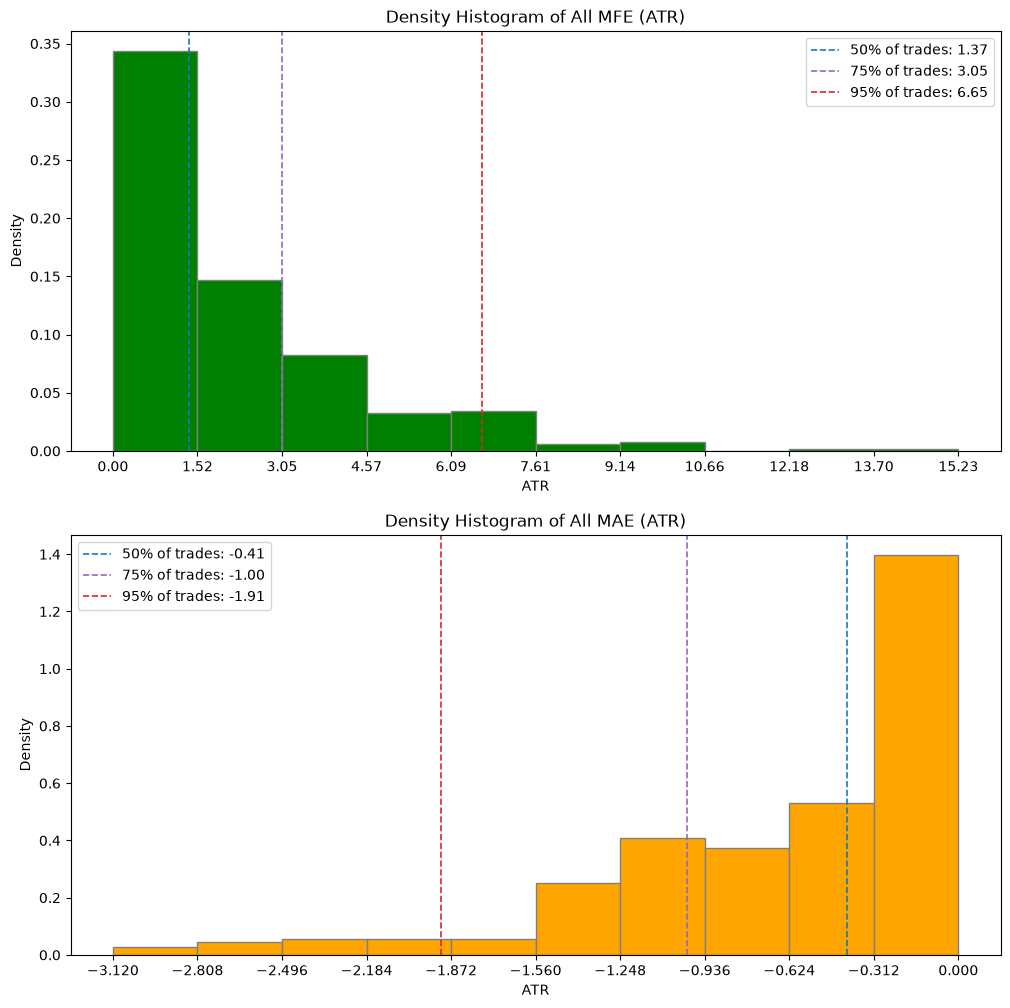

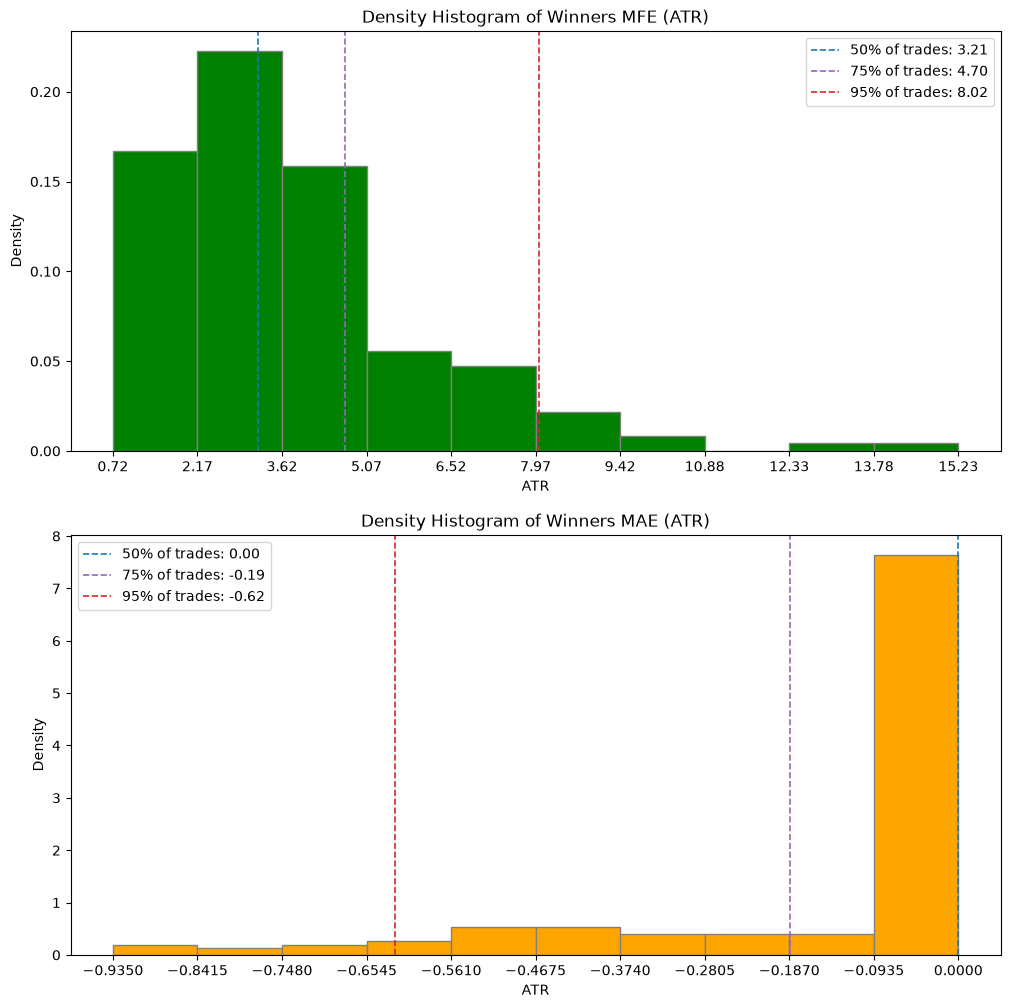

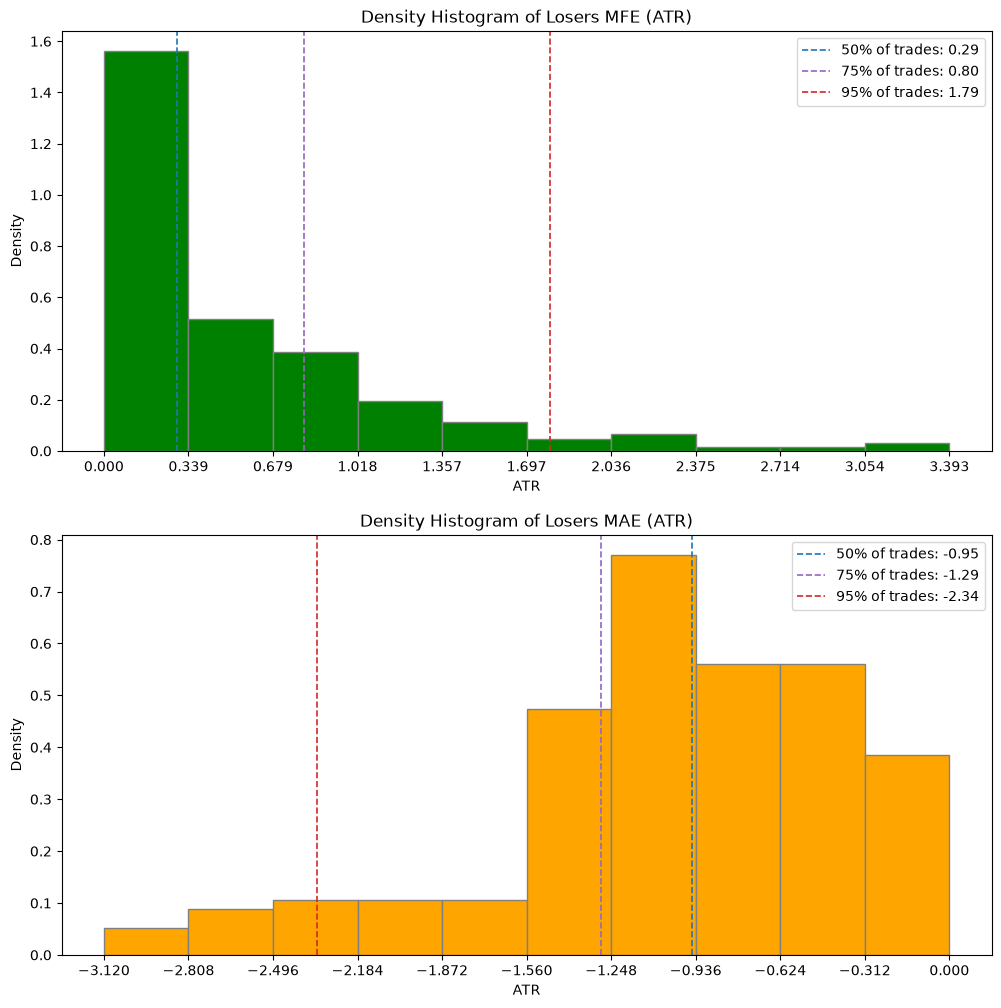

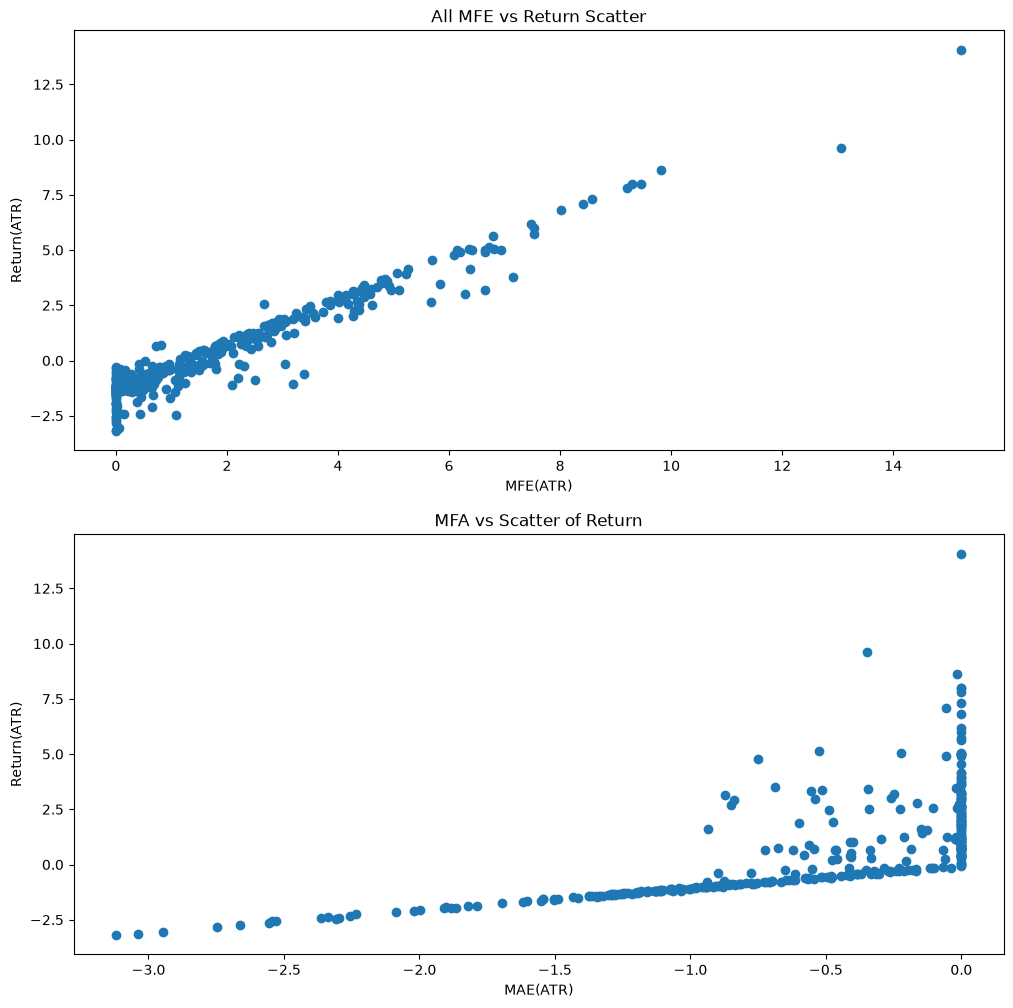

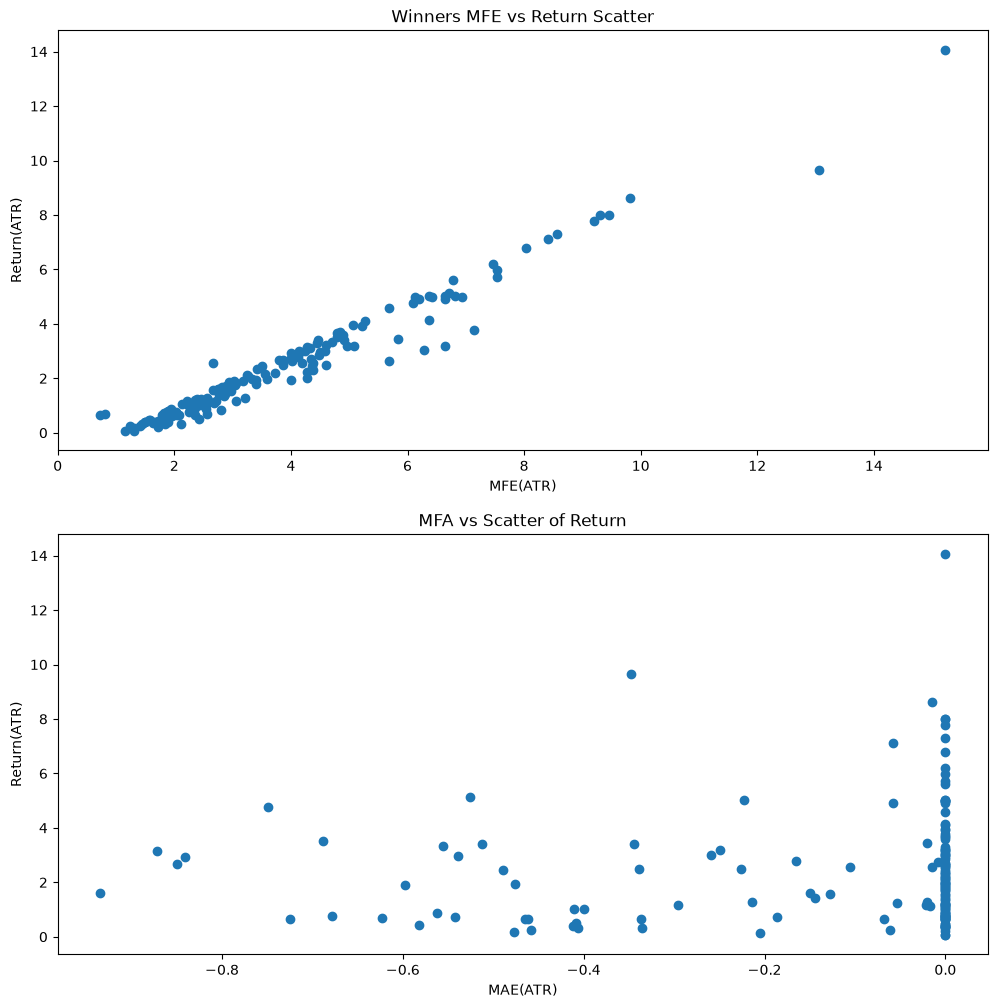

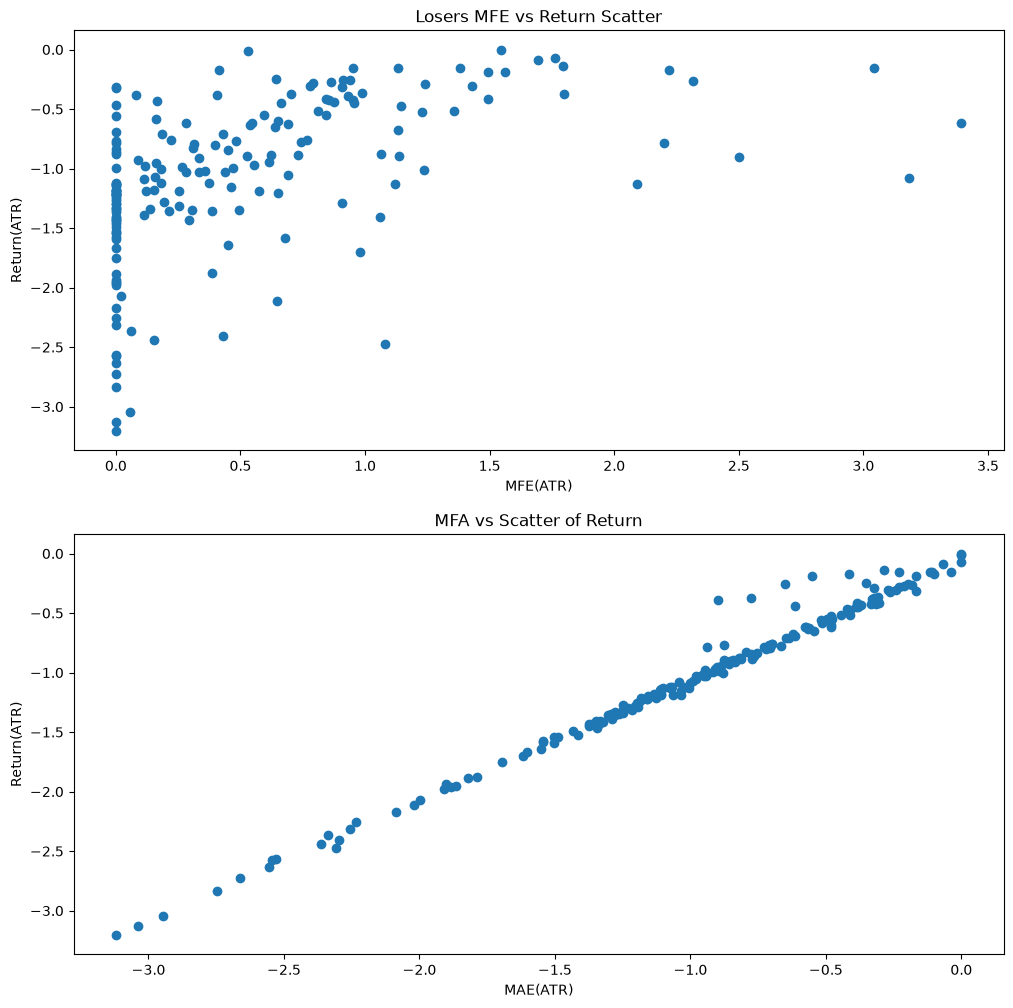

In [44]:
'''MFE and MAE plots
1) MFE and MAE histograms for all, winning and losing trades
2) Return vs MFE and Return vs MAE scatter plots

Used to determine what ATR stop to use without turning winners into losers'''
def add_cover_lines(ax, data, pcts, covers=(50, 75, 95), colors=('tab:blue', 'tab:purple', 'tab:red')):
    for p, cov, c in zip(pcts, covers, colors):
        v = np.nanpercentile(data, p)
        ax.axvline(v, ls='--', color=c, lw=1.2, label=f'{cov}% of trades: {v:.2f}')
    ax.legend()

def plot_MFE_MAE(data,title):
    fig, (ax1,ax2) = plt.subplots(2,1,figsize=(12,12))
    counts, bins, patches = ax1.hist(data['MFE_ATR'],density=True, facecolor='green', edgecolor='gray')
    ax1.set_xticks(bins)
    ax1.set_xlabel('ATR'),ax1.set_ylabel('Density'),ax1.set_title(f'{title} MFE (ATR)')
    add_cover_lines(ax1, data['MFE_ATR'], pcts=(50, 75, 95))

    counts, bins, patches = ax2.hist(data['MAE_ATR'],density=True, facecolor='orange', edgecolor='gray')
    ax2.set_xticks(bins)
    ax2.set_xlabel('ATR'),ax2.set_ylabel('Density'),ax2.set_title(f'{title} MAE (ATR)')
    add_cover_lines(ax2, data['MAE_ATR'], pcts=(50, 25, 5))

plot_MFE_MAE(trades,title = 'Density Histogram of All')
plot_MFE_MAE(trades[trades['ret_ATR']>0],title = 'Density Histogram of Winners')
plot_MFE_MAE(trades[trades['ret_ATR']<0],title = 'Density Histogram of Losers')


def scatter_ret_MFE_MAE(data,title):
    fig, (ax1,ax2) = plt.subplots(2,1,figsize=(12,12))
    ax1.scatter(data['MFE_ATR'],data['ret_ATR'])
    ax1.set_ylabel('Return(ATR)'),ax1.set_xlabel('MFE(ATR)'),ax1.set_title(title)

    ax2.scatter(data['MAE_ATR'],data['ret_ATR'])
    ax2.set_ylabel('Return(ATR)'),ax2.set_xlabel('MAE(ATR)'),ax2.set_title('MFA vs Scatter of Return')

scatter_ret_MFE_MAE(trades,title ='All MFE vs Return Scatter')
scatter_ret_MFE_MAE(trades[trades['ret_ATR']>0],title ='Winners MFE vs Return Scatter')
scatter_ret_MFE_MAE(trades[trades['ret_ATR']<0],title ='Losers MFE vs Return Scatter')


MaxDD -26.0% on 2020-06-24 | Longest underwater 534d | Median episode 5d | Time underwater 92% | Currently 179d under


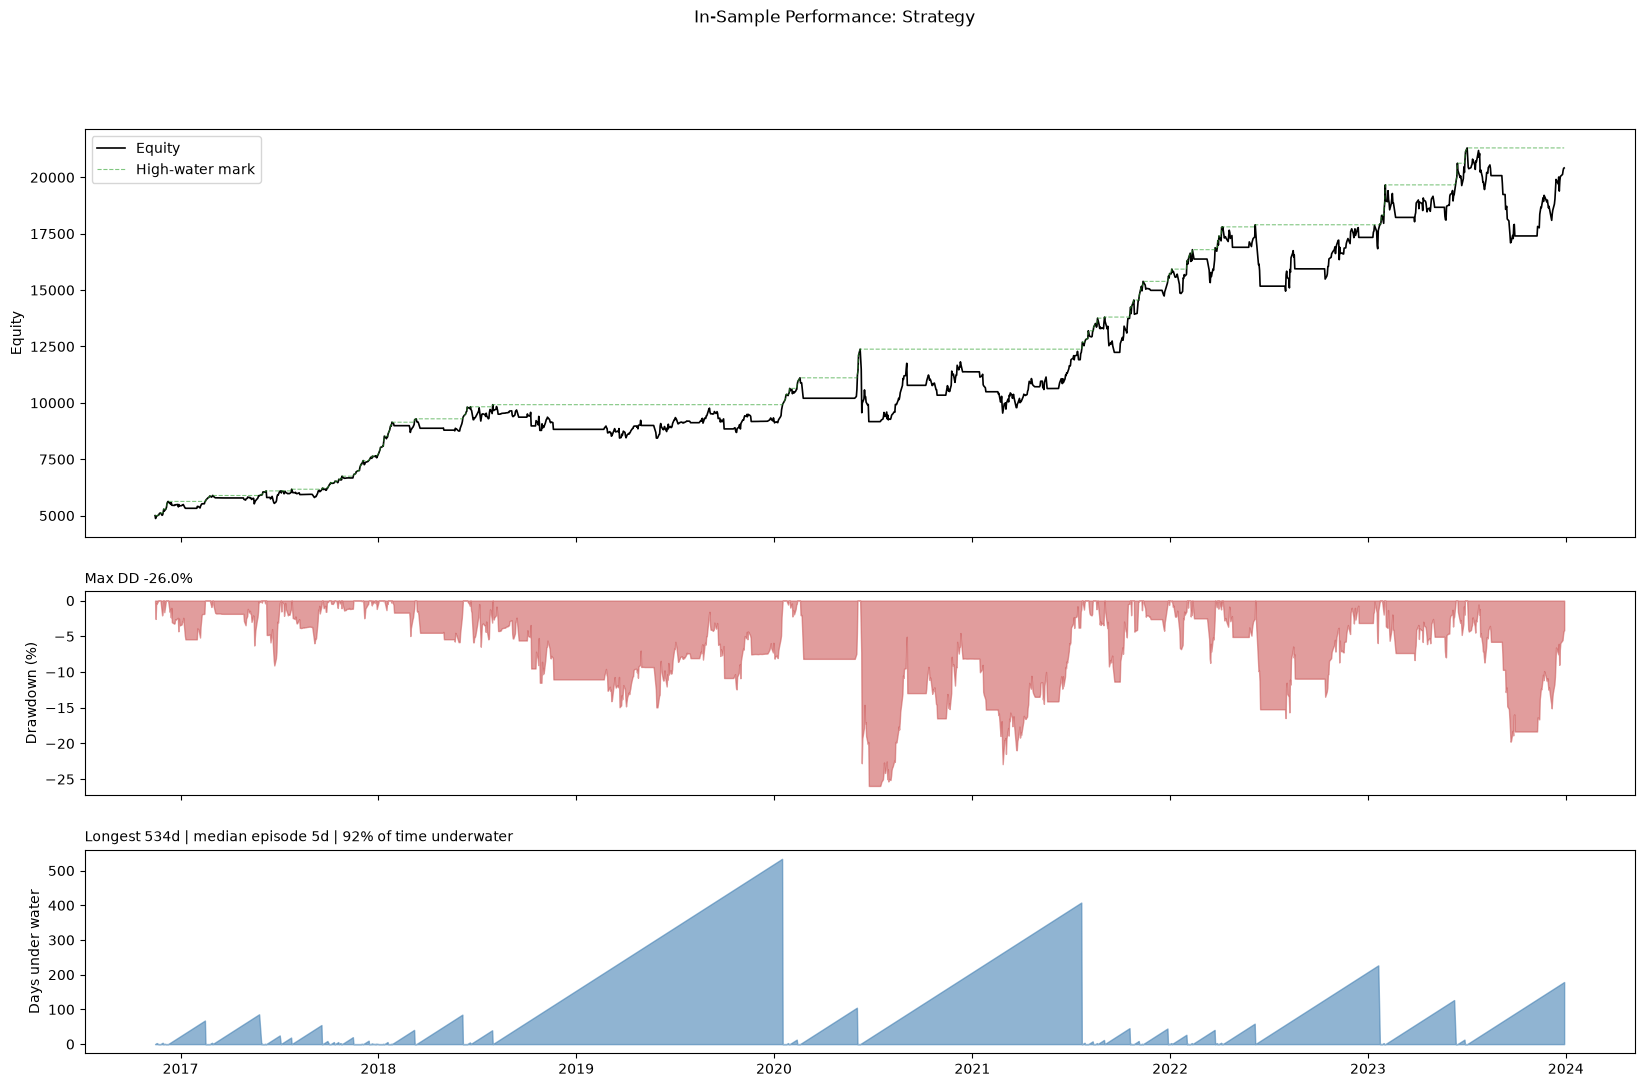

Max DD: peak 2020-06-08 -> trough 2020-06-24 -> recovered 2021-07-22
Total return (%)          308.32
CAGR (%)                   21.85
Ann. vol (%)               21.04
Sharpe                      1.05
Sortino                     1.45
Max DD (%)                -25.95
Calmar                      0.84
Max DD duration (d)       409.00
Longest underwater (d)    534.00
Time underwater (%)        91.91
Trades                    344.00
Win rate (%)               38.37
Profit factor               1.69
Payoff (avg W / avg L)      1.87
Expectancy (R)              0.09
Days in market (%)         66.69
Peak leverage (x)           2.02


In [45]:
'''Runs the portfolio, risk-managed backtest using ATR based positioning'''

PORT_RISK = 0.05
ATR_STOP_MULT = 2*TRAIL_ATR
MAX_LEVERAGE = 2


prices = (train.assign(Date=pd.to_datetime(train['Date']))
               .pivot(index='Date', columns='Ticker', values='Close').sort_index().ffill())

def backtest_mtm(trades, prices, capital=5000, risk=0.05, atr_mult=TRAIL_ATR,
                 max_lev=5, whole=False, include_open=True):
    t = (trades if include_open else trades[~trades['open']]).reset_index(drop=True).copy()
    t['entry_date'] = pd.to_datetime(t['entry_date'])
    t['exit_date']  = pd.to_datetime(t['exit_date'])

    idx = prices.index[(prices.index >= t['entry_date'].min()) &
                       (prices.index <= t['exit_date'].max())]
    ent = t.groupby('entry_date').groups
    ext = t.groupby('exit_date').groups

    cash, held = capital, set()
    shares, eq_in, lev_in = (np.zeros(len(t)) for _ in range(3))
    tick, px_in = t['Ticker'].to_numpy(), t['entry'].to_numpy()
    eq = []

    for d in idx:
        for k in ext.get(d, []):                                   # exits first
            cash += shares[k] * t.at[k, 'exit']
            held.discard(k)
        val = {k: shares[k] * prices.at[d, tick[k]] for k in held}  # mark to close

        for k in ent.get(d, []):                                   # entries
            gross  = sum(val.values())
            equity = cash + gross
            n = equity * risk / (atr_mult * t.at[k, 'ATR_entry'])
            n = min(n, max(max_lev * equity - gross, 0) / px_in[k])
            if whole: n = np.floor(n)
            shares[k], eq_in[k] = n, equity
            val[k] = n * px_in[k]
            held.add(k)
            cash -= val[k]
            lev_in[k] = sum(val.values()) / equity

        eq.append(cash + sum(val.values()))

    t['shares'], t['eq_entry'], t['lev_entry'] = shares, eq_in, lev_in
    t['pnl'] = t['shares'] * (t['exit'] - t['entry'])
    t['R']   = t['pnl'] / (t['eq_entry'] * risk)
    return t, pd.Series(eq, index=idx)

t, daily = backtest_mtm(trades, prices, risk=PORT_RISK, atr_mult=ATR_STOP_MULT, max_lev=MAX_LEVERAGE)


yrs = (daily.index[-1] - daily.index[0]).days / 365.25

def dd_plot(eq, title='Full-Sample Performance'):
    peak = eq.cummax()
    dd   = eq / peak - 1
    uw   = dd < 0

    last_peak = eq.index.to_series().where(~uw).ffill()
    tuw = (eq.index.to_series() - last_peak).dt.days

    ep  = (~uw).cumsum()
    dur = tuw.groupby(ep).max()
    dur = dur[dur > 0]

    print(f"MaxDD {dd.min():.1%} on {dd.idxmin():%Y-%m-%d} | "
          f"Longest underwater {tuw.max()}d | Median episode {dur.median():.0f}d | "
          f"Time underwater {uw.mean():.0%} | Currently {tuw.iloc[-1]}d under")

    fig, axs = plt.subplots(3, 1, figsize=(20, 12), sharex=True,
                            gridspec_kw={'height_ratios': [3, 1.5, 1.5]})

    axs[0].plot(eq, color='k', lw=1.2, label='Equity')
    axs[0].plot(peak, color='tab:green', lw=0.8, ls='--', alpha=0.6, label='High-water mark')
    axs[0].set_ylabel('Equity')
    axs[0].legend(loc='upper left')

    axs[1].fill_between(dd.index, dd * 100, 0, color='indianred', alpha=0.6)
    axs[1].set_ylabel('Drawdown (%)')
    axs[1].set_title(f'Max DD {dd.min():.1%}', loc='left', fontsize=10)

    axs[2].fill_between(tuw.index, tuw, 0, color='steelblue', alpha=0.6)
    axs[2].set_ylabel('Days under water')
    axs[2].set_title(f'Longest {tuw.max()}d | median episode {dur.median():.0f}d | '
                     f'{uw.mean():.0%} of time underwater', loc='left', fontsize=10)

    plt.suptitle(title)
    plt.show()

dd_plot(daily, 'In-Sample Performance: Strategy')


def perf_stats(daily, t=None, rf=0.0, ppy=252):
    r   = daily.pct_change().dropna()
    ex  = r - rf / ppy
    yrs = (daily.index[-1] - daily.index[0]).days / 365.25
    cagr = (daily.iloc[-1] / daily.iloc[0]) ** (1 / yrs) - 1

    peak = daily.cummax()
    dd   = daily / peak - 1
    uw   = dd < 0
    ix   = daily.index.to_series()
    tuw  = (ix - ix.where(~uw).ffill()).dt.days

    trough = dd.idxmin()
    hi     = peak[trough]
    pre    = daily.loc[:trough]
    pk     = pre[pre >= hi].index[-1]                    # last day at the high before the trough
    post   = daily.loc[trough:]
    rec    = post[post >= hi].index
    rec    = rec[0] if len(rec) else None
    end    = rec if rec is not None else daily.index[-1]
    print(f"Max DD: peak {pk:%Y-%m-%d} -> trough {trough:%Y-%m-%d} -> "
          + (f"recovered {rec:%Y-%m-%d}" if rec is not None else "NOT recovered"))

    out = {
        'Total return (%)':        100 * (daily.iloc[-1] / daily.iloc[0] - 1),
        'CAGR (%)':                100 * cagr,
        'Ann. vol (%)':            100 * r.std() * np.sqrt(ppy),
        'Sharpe':                  ex.mean() / ex.std() * np.sqrt(ppy),
        'Sortino':                 ex.mean() / np.sqrt((np.minimum(ex, 0) ** 2).mean()) * np.sqrt(ppy),
        'Max DD (%)':              100 * dd.min(),
        'Calmar':                  cagr / abs(dd.min()),
        'Max DD duration (d)':     (end - pk).days,
        'Longest underwater (d)':  tuw.max(),
        'Time underwater (%)':     100 * uw.mean(),
    }

    if t is not None:
        pnl = t['pnl']
        win, loss = pnl[pnl > 0], pnl[pnl < 0]
        n_open = (t.groupby('entry_date').size()
                    .sub(t.groupby('exit_date').size(), fill_value=0)
                    .reindex(daily.index, fill_value=0).cumsum())
        out.update({
            'Trades':                  len(t),
            'Win rate (%)':            100 * (pnl > 0).mean(),
            'Profit factor':           win.sum() / -loss.sum(),
            'Payoff (avg W / avg L)':  win.mean() / -loss.mean(),
            'Expectancy (R)':          t['R'].mean(),
            'Days in market (%)':      100 * (n_open > 0).mean(),
            'Peak leverage (x)':       t['lev_entry'].max(),
        })

    return pd.Series(out)

stats = perf_stats(daily, t, rf=0.0)   
print(stats.round(2).to_string())

rho = 0.33461196012406996
S_i = 0.7678700577389543
rho*S_p = 0.35064630290552207
W_i = 0.36990351038456787
=== SPY ===


Annualised_Return         0.135382
Annualised_Vol            0.189029
Max_Drawdown             -0.337173
Max_DD_Duration_Days    173.000000
Sharpe                    0.767870
Sortino                   1.068701
dtype: float64

=== Trend Following ===


Annualised_Return         0.218524
Annualised_Vol            0.210381
Max_Drawdown             -0.259504
Max_DD_Duration_Days    409.000000
Sharpe                    1.047919
Sortino                   1.448697
dtype: float64

=== MIX ===


Annualised_Return        0.194580
Annualised_Vol           0.169305
Max_Drawdown            -0.191339
Max_DD_Duration_Days    86.000000
Sharpe                   1.137611
Sortino                  1.569981
dtype: float64

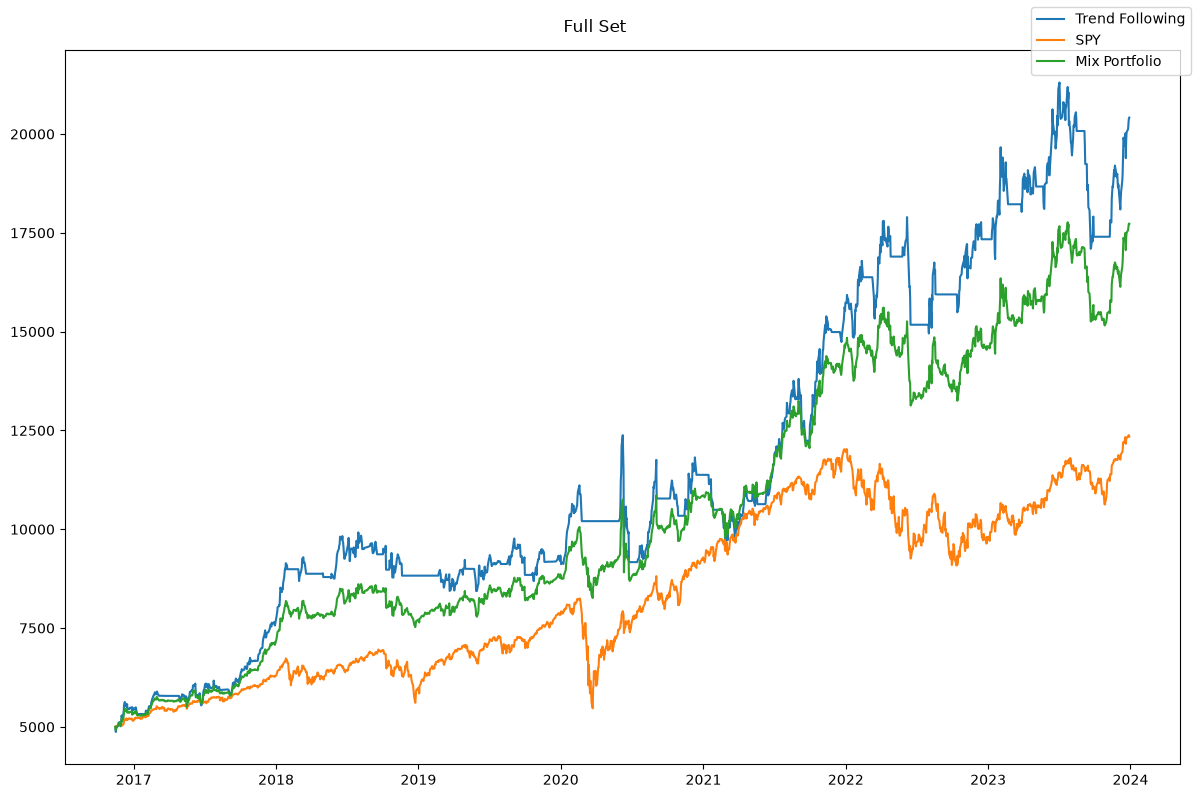

In [46]:
'''Compares the strategy to SPY, and computes optimal weighting to maximise sharpe when including SPY '''

spy = yf.download('SPY', start=daily.index.min(),
                  end=daily.index.max() + pd.Timedelta(days=1),
                  auto_adjust=True, progress=False)['Close'].squeeze()

spy = spy.reindex(daily.index).ffill()      # force identical dates
SPY_port = daily.iloc[0] * spy / spy.iloc[0]
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(daily, label = 'Trend Following')
ax.plot(SPY_port, label = 'SPY')


rho = np.corrcoef(daily.pct_change().dropna(), SPY_port.pct_change().dropna())[0,1]
print(f'rho = {rho}')

def combine(daily, spy_port, W_i, W_P, rebalance=True):
    """W_i = SPY weight, W_P = strategy weight. Weights not summing to 1 leave the remainder in cash at 0%."""
    spy_n = spy_port / spy_port.iloc[0]
    p_n   = daily / daily.iloc[0]

    if rebalance:   # constant weights, rebalanced every day
        r  = W_i * spy_n.pct_change() + W_P * p_n.pct_change()
        eq = (1 + r.fillna(0)).cumprod()
    else:           # buy and hold, weights drift
        eq = W_i * spy_n + W_P * p_n

    return daily.iloc[0] * eq

def performance_stats(equity_df, rf=0.0, ppy=252):
    """rf = annual risk-free rate as a decimal (e.g. 0.04)."""
    v = equity_df.astype(float).squeeze()
    v.index = pd.to_datetime(v.index)

    r   = v.pct_change().dropna()
    ex  = r - rf / ppy
    yrs = (v.index[-1] - v.index[0]).days / 365.25
    cagr = (v.iloc[-1] / v.iloc[0]) ** (1 / yrs) - 1
    vol  = r.std() * np.sqrt(ppy)

    peak = v.cummax()
    dd   = v / peak - 1

    trough = dd.idxmin()
    hi     = peak[trough]
    pre    = v.loc[:trough]
    pk     = pre[pre >= hi].index[-1]
    post   = v.loc[trough:]
    rec    = post[post >= hi].index
    end    = rec[0] if len(rec) else v.index[-1]
    dd_dur = (end - pk).days

    dn = np.sqrt((np.minimum(ex, 0) ** 2).mean())

    return pd.Series({'Annualised_Return':   cagr,
                      'Annualised_Vol':      vol,
                      'Max_Drawdown':        dd.min(),
                      'Max_DD_Duration_Days': dd_dur,
                      'Sharpe':  ex.mean() / ex.std() * np.sqrt(ppy) if ex.std() else np.nan,
                      'Sortino': ex.mean() / dn * np.sqrt(ppy) if dn else np.nan})

spy_stats = performance_stats(SPY_port)
port_stats = performance_stats(daily)

S_i,S_p = spy_stats['Sharpe'], port_stats['Sharpe']
sigma_i, sigma_p = spy_stats['Annualised_Vol'], port_stats['Annualised_Vol']
print(f'S_i = {S_i}')
print(f'rho*S_p = {rho*S_p}')

'''Markowitz 1952: Can increase sharpe iff S_i > rho*S_P'''
W_i = (sigma_p*(S_i - rho*S_p))/(sigma_i*(S_p - rho*S_i)+sigma_p*(S_i - rho*S_p))
print(f'W_i = {W_i}')

mix = combine(daily, SPY_port, W_i=W_i, W_P=(1- W_i)) #obviously would want to use weights from training on a test set
ax.plot(mix, label = 'Mix Portfolio')
fig.suptitle('Full Set')
fig.tight_layout()
fig.legend()

print('=== SPY ===')
display(spy_stats)
print('=== Trend Following ===')
display(port_stats)
print('=== MIX ===')
display(performance_stats(mix))

Max DD: peak 2020-06-08 -> trough 2020-06-24 -> recovered 2021-07-22
Max DD: peak 2020-02-19 -> trough 2020-03-23 -> recovered 2020-08-10
Max DD: peak 2020-06-08 -> trough 2020-06-26 -> recovered 2020-09-02
                        Strategy     SPY     Mix
Ann. vol (%)               21.04   18.90   16.93
CAGR (%)                   21.85   13.54   19.46
Calmar                      0.84    0.40    1.02
Days in market (%)         66.69     NaN     NaN
Expectancy (R)              0.09     NaN     NaN
Longest underwater (d)    534.00  708.00  388.00
Max DD (%)                -25.95  -33.72  -19.13
Max DD duration (d)       409.00  173.00   86.00
Payoff (avg W / avg L)      1.87     NaN     NaN
Peak leverage (x)           2.02     NaN     NaN
Profit factor               1.69     NaN     NaN
Sharpe                      1.05    0.77    1.14
Sortino                     1.45    1.07    1.57
Time underwater (%)        91.91   85.38   89.73
Total return (%)          308.32  146.90  254.53
Trades   

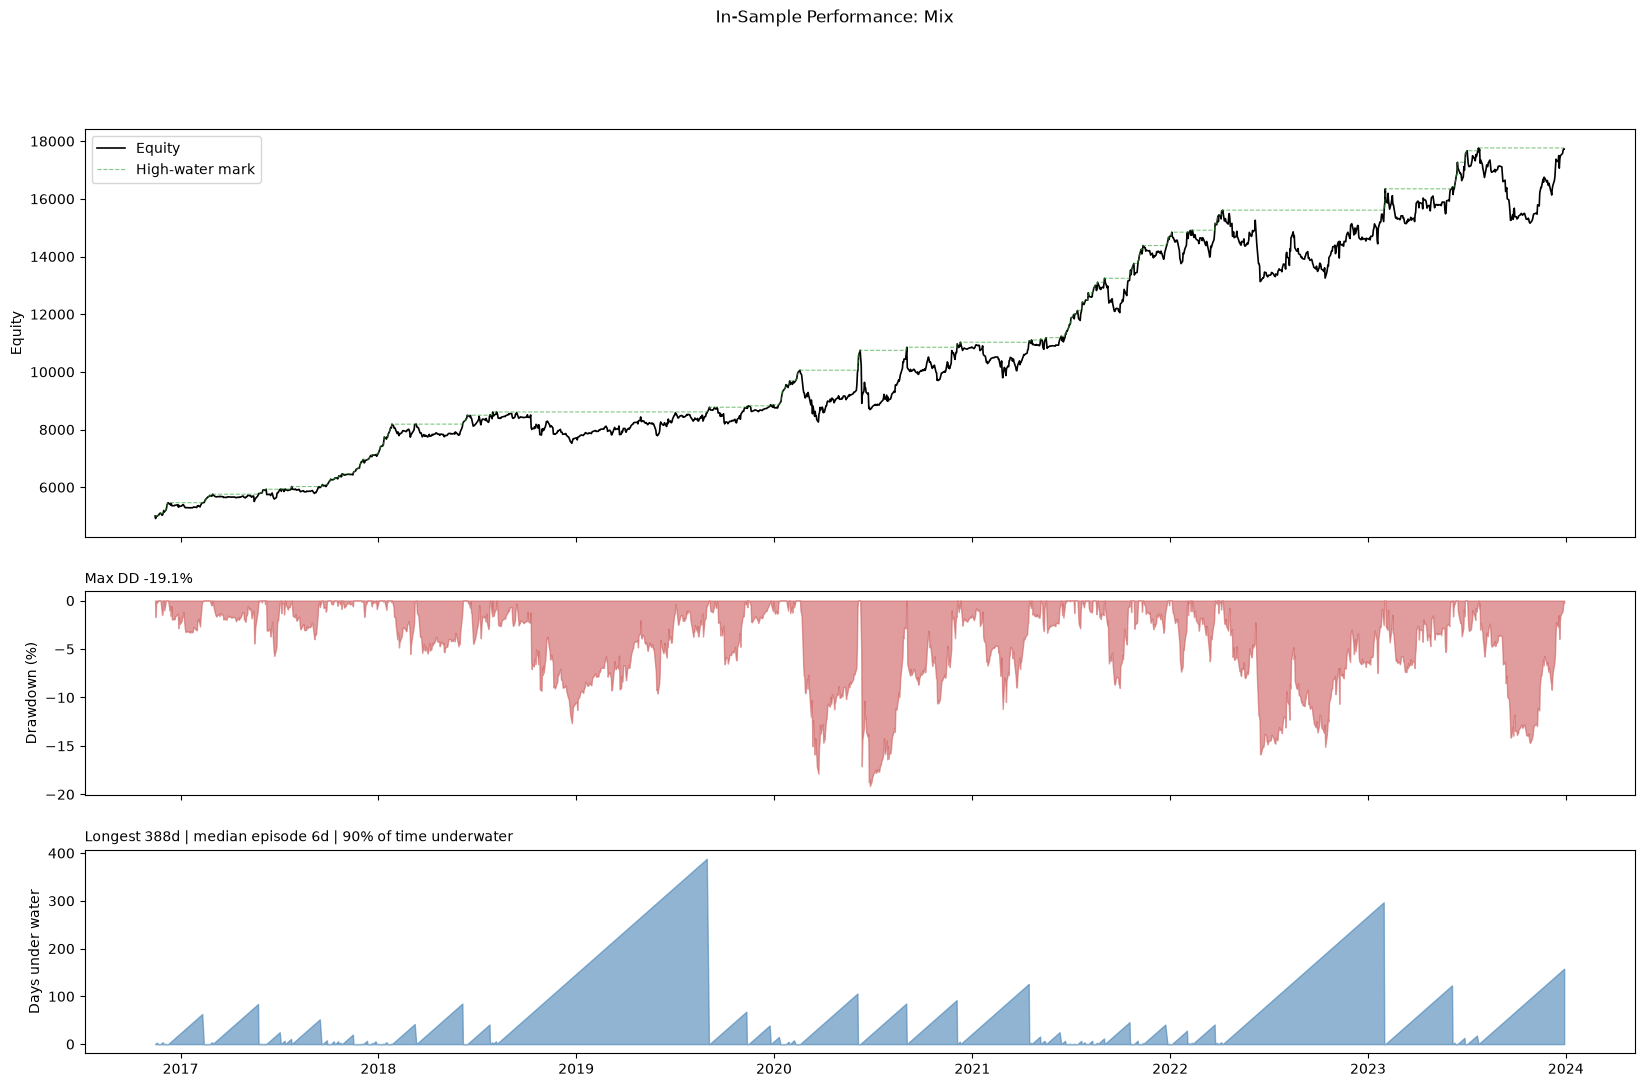

In [47]:
'''Compares the stats between the raw stategy, SPY, and a mix of the two'''
stats = pd.DataFrame({
    'Strategy': perf_stats(daily, t),
    'SPY':      perf_stats(SPY_port),
    'Mix':      perf_stats(mix),
})
print(stats.round(2).to_string())
dd_plot(mix,   'In-Sample Performance: Mix')

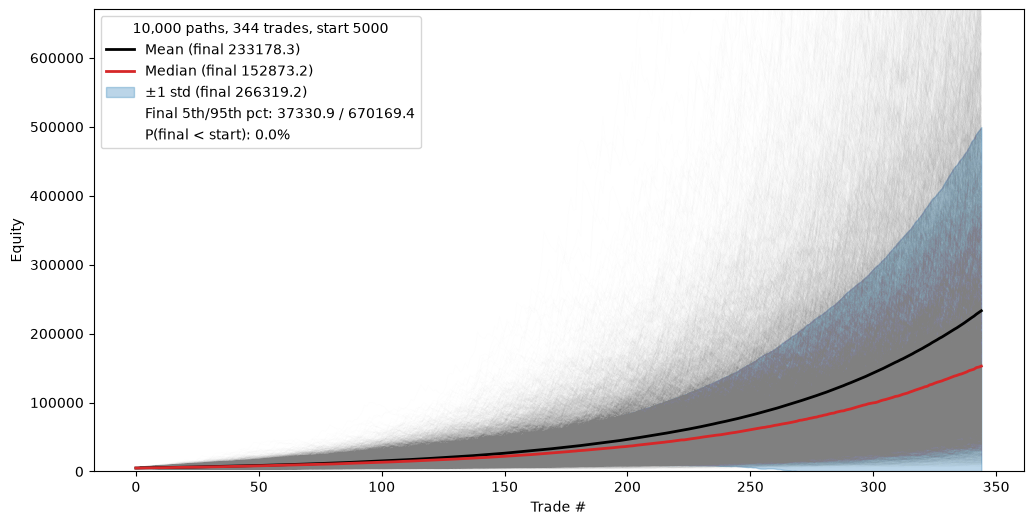

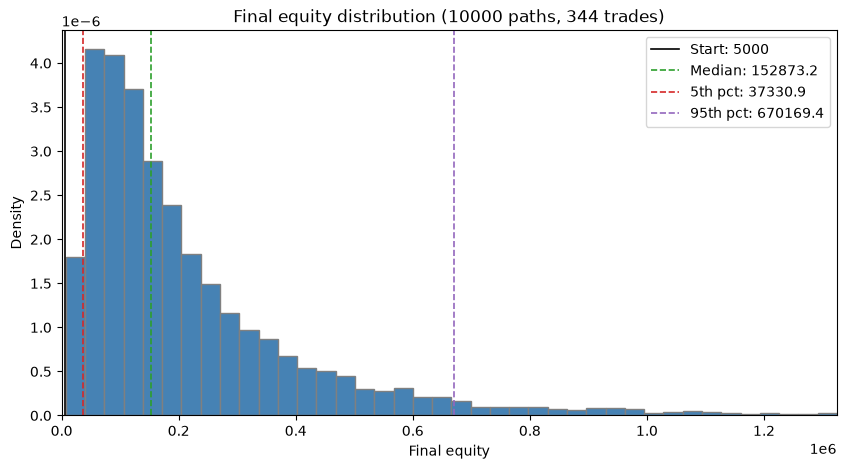

P(loss): 0.0%


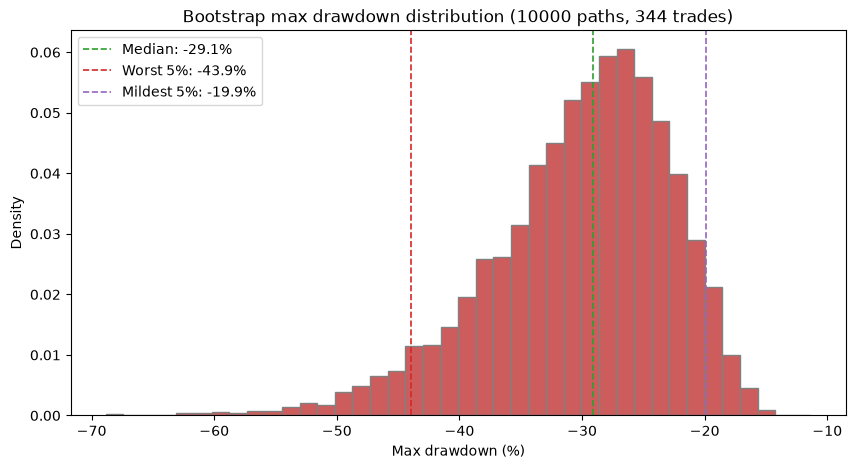

P(maxDD worse than -20%): 94.7%


In [48]:
'''Bootstrap of trades using ATR position sizing.
Assumptions:
 - Trades are IID
 - Trades are sequential and not concurrent
 - Sizing is per trades only
 '''
rng = np.random.default_rng(420)
RISK, ATR_MULT, MAX_LEV = 0.05, 2, 2

ret     = closed['ret%'].to_numpy() / 100
atr_pct = closed['ATR_pct'].to_numpy() / 100
w       = np.minimum(RISK / (ATR_MULT * atr_pct), MAX_LEV)
r_eq    = w * ret                                   # return on equity per trade

N_PATHS, L, START = 10000, len(t), 5000
idx     = rng.integers(0, len(r_eq), size=(N_PATHS, L))
samples = r_eq[idx]                                 # resamples (ret, ATR) as a pair
equity = START * np.cumprod(1 + samples, axis=1)
equity = np.hstack([np.full((N_PATHS, 1), START), equity])   # start all paths at START

mean, std = equity.mean(axis=0), equity.std(axis=0)
med = np.median(equity, axis=0)
x = np.arange(L + 1)

final = equity[:, -1]
p5, p95,p99 = np.percentile(final, [5, 95,99])
p_loss = (final < START).mean()

cap = p95
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(x, equity.T, color='gray', alpha=0.01, lw=0.7)
ax.plot(x, mean, color='k', lw=2, label=f'Mean (final {mean[-1]:.1f})')
ax.plot(x, med, color='tab:red', lw=2, label=f'Median (final {med[-1]:.1f})')
ax.fill_between(x, mean - std, mean + std, color='tab:blue', alpha=0.3,
                label=f'±1 std (final {std[-1]:.1f})')
ax.plot([], [], ' ', label=f'Final 5th/95th pct: {p5:.1f} / {p95:.1f}')
ax.plot([], [], ' ', label=f'P(final < start): {p_loss:.1%}')
ax.set_ylim(0, cap)
ax.set_xlabel('Trade #')
ax.set_ylabel('Equity')
ax.legend(title=f'{N_PATHS:,} paths, {L} trades, start {START}', loc='upper left')
plt.show()

final = equity[:, -1]
p5, med, p95 = np.percentile(final, [5, 50, 95])

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(final, bins=200, density=True, facecolor='steelblue', edgecolor='gray')
ax.axvline(START, color='k', lw=1.2, label=f'Start: {START}')
ax.axvline(med, color='tab:green', ls='--', lw=1.2, label=f'Median: {med:.1f}')
ax.axvline(p5, color='tab:red', ls='--', lw=1.2, label=f'5th pct: {p5:.1f}')
ax.axvline(p95, color='tab:purple', ls='--', lw=1.2, label=f'95th pct: {p95:.1f}')
ax.set_xlabel('Final equity')
ax.set_ylabel('Density')
ax.set_xlim(0,p99)
ax.set_title(f'Final equity distribution ({N_PATHS} paths, {L} trades)')
ax.legend()
plt.show()

print(f'P(loss): {(final < START).mean():.1%}')

peak = np.maximum.accumulate(equity, axis=1)
maxdd = (equity / peak - 1).min(axis=1) * 100          # % , negative

d5, dmed, d95 = np.percentile(maxdd, [5, 50, 95])       # d5 = worst 5%

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(maxdd, bins=40, density=True, facecolor='indianred', edgecolor='gray')
ax.axvline(dmed, color='tab:green', ls='--', lw=1.2, label=f'Median: {dmed:.1f}%')
ax.axvline(d5, color='tab:red', ls='--', lw=1.2, label=f'Worst 5%: {d5:.1f}%')
ax.axvline(d95, color='tab:purple', ls='--', lw=1.2, label=f'Mildest 5%: {d95:.1f}%')
ax.set_xlabel('Max drawdown (%)')
ax.set_ylabel('Density')
ax.set_title(f'Bootstrap max drawdown distribution ({N_PATHS} paths, {L} trades)')
ax.legend()
plt.show()

print(f'P(maxDD worse than -20%): {(maxdd < -20).mean():.1%}')